# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Nurmi Laziva
- **Email:** nurminlaziva@gmail.com
- **ID Dicoding:** nurmi_lazivavl0k

## Menentukan Pertanyaan Bisnis

### Konteks dan Definisi

Dataset berisi transaksi marketplace Olist di Brasil dalam sembilan tabel: pelanggan, pesanan, item pesanan, pembayaran, ulasan, produk, penjual, terjemahan kategori produk, dan koordinat kode pos. Pesanan tercatat dari September 2016 sampai Oktober 2018. Hanya Januari 2017 sampai Agustus 2018 yang memiliki data bulanan berkelanjutan, dengan 800 sampai 7.544 pesanan per bulan. Bulan di luar rentang itu hanya memuat 349 dari 99.441 pesanan (0,35%). Rentang Januari 2017-Agustus 2018 karena itu dijadikan periode analisis.

Definisi berikut berlaku di seluruh notebook dan dashboard.

| Istilah | Definisi |
|---|---|
| Pesanan valid | Status `delivered` dan tanggal tiba di pelanggan terisi |
| Revenue | Jumlah `price` seluruh item pada pesanan valid, tidak termasuk ongkos kirim (`freight_value`). Satuan: real Brasil (R$) |
| Pesanan terlambat | Tanggal tiba (dihitung per hari kalender) lebih besar dari tanggal estimasi pengiriman |
| Durasi pengiriman | Selang waktu dari pembelian sampai barang tiba di pelanggan, dalam hari |
| Review score | Skor ulasan 1-5. Bila satu pesanan memiliki beberapa ulasan, dipakai ulasan terakhir |
| Pelanggan | `customer_unique_id`. Kolom `customer_id` berganti pada setiap pesanan sehingga tidak dapat dipakai untuk menghitung pembelian ulang |

### Pertanyaan Bisnis

Pertanyaan disusun dengan kerangka **SMART** (Specific, Measurable, Action-oriented, Relevant, Time-bound).

- **Pertanyaan 1:** Berapa pertumbuhan revenue dan jumlah pesanan pada Januari-Agustus 2018 dibandingkan Januari-Agustus 2017, kategori produk mana yang memberi kenaikan revenue terbesar, dan apakah revenue bulanan sepanjang 2018 masih naik?
  - *Specific:* revenue dan jumlah pesanan berstatus `delivered`, dirinci per kategori produk dan per bulan.
  - *Measurable:* persentase pertumbuhan year-over-year, kontribusi tiap kategori terhadap total kenaikan revenue (R$ dan persen), dan perubahan revenue bulanan Januari-Agustus 2018.
  - *Action-oriented:* menentukan kategori yang diprioritaskan untuk stok dan promosi, serta menilai perlunya stimulus penjualan bila revenue bulanan tidak lagi naik.
  - *Relevant:* pertumbuhan penjualan adalah indikator utama kinerja sebuah marketplace.
  - *Time-bound:* Januari-Agustus 2018 dibandingkan dengan Januari-Agustus 2017.
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata review score antara pesanan tepat waktu dan terlambat selama Januari 2017–Agustus 2018, dan di negara bagian mana persentase pesanan terlambat paling tinggi?
  - *Specific:* hubungan status keterlambatan dengan review score, dan sebaran keterlambatan per negara bagian pelanggan. Pendalaman: apakah jarak penjual ke pelanggan menjelaskan perbedaan antarwilayah (bagian Analisis Lanjutan).
  - *Measurable:* selisih rata-rata review score antara pesanan terlambat dan tepat waktu, persentase ulasan 1-2 bintang, dan persentase pesanan terlambat per negara bagian.
  - *Action-oriented:* menentukan wilayah yang diprioritaskan untuk perbaikan logistik atau penyesuaian estimasi pengiriman.
  - *Relevant:* ulasan memengaruhi reputasi penjual dan keputusan beli calon pelanggan, sedangkan keterlambatan adalah faktor operasional yang dapat dikendalikan.
  - *Time-bound:* pesanan dengan tanggal pembelian Januari 2017-Agustus 2018.
- **Pertanyaan 3:** Berapa persen pelanggan yang membeli lebih dari satu kali selama Januari 2017-Agustus 2018, dan segmen RFM mana (tanggal acuan 1 September 2018) yang menyumbang revenue terbesar sehingga layak diprioritaskan untuk kampanye pembelian ulang? (dijawab pada bagian Analisis Lanjutan)
  - *Specific:* pelanggan unik yang bertransaksi lebih dari sekali, dan segmentasi pelanggan berdasarkan recency, frequency, dan monetary.
  - *Measurable:* persentase pelanggan yang membeli ulang, serta persentase pelanggan dan persentase revenue pada tiap segmen.
  - *Action-oriented:* menentukan segmen sasaran kampanye pembelian ulang dan win-back.
  - *Relevant:* pembelian ulang menentukan seberapa besar pertumbuhan masih bergantung pada akuisisi pelanggan baru.
  - *Time-bound:* Januari 2017-Agustus 2018, dengan recency dihitung sampai 1 September 2018.

## Import Semua Packages/Library yang Digunakan

Parameter periode analisis, tanggal acuan RFM, dan batas koordinat didefinisikan sekali di sini agar seluruh sel berikutnya memakai nilai yang sama. Path dibuat relatif terhadap root folder proyek (folder yang berisi `data/` dan `dashboard/`), sehingga notebook dapat dijalankan di mesin lokal maupun di Colab selama struktur folder proyek tersedia.

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.options.display.float_format = "{:,.2f}".format

# Lokasi folder proyek. Notebook dijalankan dari root folder submission
# (folder yang berisi data/ dan dashboard/); jika dijalankan dari subfolder,
# root dicari satu tingkat di atasnya.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists() and (BASE_DIR.parent / "data").exists():
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data"
DASHBOARD_DIR = BASE_DIR / "dashboard"
MAIN_DATA_PATH = DASHBOARD_DIR / "main_data.csv"

assert DATA_DIR.exists(), (
    "Folder 'data' tidak ditemukan. Jalankan notebook dari root folder proyek "
    "(folder yang berisi data/, dashboard/, dan notebook.ipynb)."
)

# Parameter analisis yang dipakai di seluruh notebook
PERIODE_AWAL = pd.Timestamp("2017-01-01")
PERIODE_AKHIR = pd.Timestamp("2018-08-31")
TANGGAL_ACUAN_RFM = PERIODE_AKHIR + pd.Timedelta(days=1)   # 1 September 2018

# Kotak batas kasar wilayah Brasil (termasuk pulau lepas pantai seperti Fernando de Noronha)
BRAZIL_LAT_RANGE = (-33.75, 5.28)
BRAZIL_LNG_RANGE = (-73.99, -28.84)
BATAS_JARAK_STATE_KM = 1500   # titik zip yang lebih jauh dari ini terhadap median state-nya dianggap keliru


def haversine_km(lat1, lng1, lat2, lng2):
    """Jarak lingkaran besar (km) antara dua titik koordinat dalam derajat."""
    radius_bumi = 6371.0088
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    d_phi = phi2 - phi1
    d_lambda = np.radians(lng2) - np.radians(lng1)
    a = np.sin(d_phi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(d_lambda / 2) ** 2
    return 2 * radius_bumi * np.arcsin(np.sqrt(a))

## Data Wrangling

### Gathering Data

#### Load seluruh tabel mentah

Sembilan berkas CSV pada folder `data/` dimuat ke DataFrame tanpa transformasi. Relasi antartabel: `orders.customer_id` ke `customers`; `order_items.order_id` ke `orders`; `order_items.product_id` ke `products`; `order_items.seller_id` ke `sellers`; `order_reviews.order_id` dan `order_payments.order_id` ke `orders`; kode pos pelanggan dan penjual ke `geolocation`; `products.product_category_name` ke `category_translation`.

In [2]:
customers_df = pd.read_csv(DATA_DIR / "customers_dataset.csv")
geolocation_df = pd.read_csv(DATA_DIR / "geolocation_dataset.csv")
order_items_df = pd.read_csv(DATA_DIR / "order_items_dataset.csv")
order_payments_df = pd.read_csv(DATA_DIR / "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(DATA_DIR / "order_reviews_dataset.csv")
orders_df = pd.read_csv(DATA_DIR / "orders_dataset.csv")
products_df = pd.read_csv(DATA_DIR / "products_dataset.csv")
sellers_df = pd.read_csv(DATA_DIR / "sellers_dataset.csv")
category_translation_df = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

tabel_mentah = {
    "customers": customers_df,
    "geolocation": geolocation_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "orders": orders_df,
    "products": products_df,
    "sellers": sellers_df,
    "category_translation": category_translation_df,
}

ringkasan_tabel = pd.DataFrame({
    "tabel": list(tabel_mentah),
    "jumlah_baris": [len(df) for df in tabel_mentah.values()],
    "jumlah_kolom": [df.shape[1] for df in tabel_mentah.values()],
    "kolom": [", ".join(df.columns) for df in tabel_mentah.values()],
})
pd.set_option("display.max_colwidth", 120)
ringkasan_tabel

,tabel,jumlah_baris,jumlah_kolom,kolom
0,customers,99441,5,"customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state"
1,geolocation,1000163,5,"geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state"
2,order_items,112650,7,"order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value"
3,order_payments,103886,5,"order_id, payment_sequential, payment_type, payment_installments, payment_value"
4,order_reviews,99224,7,"review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer..."
5,orders,99441,8,"order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, orde..."
6,products,32951,9,"product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weig..."
7,sellers,3095,4,"seller_id, seller_zip_code_prefix, seller_city, seller_state"
8,category_translation,71,2,"product_category_name, product_category_name_english"


#### Pratinjau isi tabel

In [3]:
for nama, df in tabel_mentah.items():
    print(f"=== {nama} {df.shape} ===")
    display(df.head(3))

=== customers (99441, 5) ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


=== geolocation (1000163, 5) ===


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


=== order_items (112650, 7) ===


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00


=== sellers (3095, 4) ===


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


=== category_translation (71, 2) ===


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


**Insight:**
- Tabel terbesar adalah `geolocation` (1.000.163 baris), diikuti `order_items` (112.650) dan `order_payments` (103.886). Tabel `orders` memuat 99.441 pesanan dari 96.096 pelanggan unik (`customer_unique_id`).
- Seluruh kolom waktu pada `orders` terbaca sebagai teks dan harus dikonversi ke tipe datetime sebelum dihitung.
- Satu pesanan dapat memuat beberapa item dan beberapa penjual. Analisis tingkat pesanan dan tingkat item karena itu harus dipisahkan agar tidak terjadi penghitungan ganda.

### Assessing Data

#### Identifying missing value

In [4]:
def laporan_missing(tabel):
    """Ringkas kolom yang memiliki nilai kosong pada setiap tabel."""
    baris = []
    for nama, df in tabel.items():
        kosong = df.isna().sum()
        for kolom, jumlah in kosong[kosong > 0].items():
            baris.append({
                "tabel": nama,
                "kolom": kolom,
                "jumlah_missing": int(jumlah),
                "persen": round(jumlah / len(df) * 100, 2),
            })
    return pd.DataFrame(baris)


display(laporan_missing(tabel_mentah))

# Tanggal tiba yang kosong dibandingkan dengan status pesanan
tanggal_tiba_terisi = orders_df["order_delivered_customer_date"].notna().map(
    {True: "ada tanggal tiba", False: "tanpa tanggal tiba"}
)
display(pd.crosstab(orders_df["order_status"], tanggal_tiba_terisi))

,tabel,kolom,jumlah_missing,persen
0,order_reviews,review_comment_title,87656,88.34
1,order_reviews,review_comment_message,58247,58.70
2,orders,order_approved_at,160,0.16
3,orders,order_delivered_carrier_date,1783,1.79
4,orders,order_delivered_customer_date,2965,2.98
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


order_delivered_customer_date,ada tanggal tiba,tanpa tanggal tiba
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


**Temuan:** Kolom `review_comment_title` (88,3%) dan `review_comment_message` (58,7%) paling banyak kosong, tetapi keduanya tidak dipakai dalam analisis. Pada `orders`, 2.965 pesanan tidak memiliki tanggal tiba. Sebanyak 8 di antaranya berstatus `delivered`, artinya tanggal tiba hilang pada pesanan yang seharusnya sudah sampai, sementara 6 pesanan `canceled` justru memiliki tanggal tiba. Pada `products`, 610 produk (1,85%) tidak memiliki kategori.

#### Identifying duplicate data

In [5]:
duplikat = pd.DataFrame({
    "tabel": list(tabel_mentah),
    "jumlah_baris": [len(df) for df in tabel_mentah.values()],
    "baris_duplikat_penuh": [int(df.duplicated().sum()) for df in tabel_mentah.values()],
})
duplikat["persen"] = duplikat["baris_duplikat_penuh"] / duplikat["jumlah_baris"] * 100
display(duplikat)

# Duplikasi pada kunci bisnis: satu pesanan seharusnya hanya memiliki satu ulasan
ulasan_per_order = order_reviews_df.groupby("order_id").size()
order_multi_ulasan = ulasan_per_order[ulasan_per_order > 1].index
skor_berbeda = (
    order_reviews_df[order_reviews_df["order_id"].isin(order_multi_ulasan)]
    .groupby("order_id")["review_score"].nunique()
)
print(f"Baris ulasan                                  : {len(order_reviews_df):,}")
print(f"Pesanan unik pada tabel ulasan                : {ulasan_per_order.size:,}")
print(f"Pesanan dengan lebih dari satu ulasan         : {len(order_multi_ulasan):,}")
print(f"  di antaranya dengan skor yang berbeda       : {(skor_berbeda > 1).sum():,}")
print(f"Baris dengan review_id yang muncul >1 kali    : {order_reviews_df['review_id'].duplicated(keep=False).sum():,}")

# Audit tambahan: review_id yang dipakai untuk lebih dari satu order_id.
# Tidak menghapus baris secara arbitrer karena tidak ada pemetaan otoritatif di sumber.
orders_per_review_id = order_reviews_df.groupby("review_id")["order_id"].nunique(dropna=True)
review_id_multi_order = orders_per_review_id[orders_per_review_id > 1]
rows_multi_review_id = order_reviews_df[order_reviews_df["review_id"].isin(review_id_multi_order.index)]
print(f"review_id unik                                : {order_reviews_df['review_id'].nunique():,}")
print(f"review_id terkait >1 order_id                 : {len(review_id_multi_order):,}")
print(f"Baris pada review_id lintas order              : {len(rows_multi_review_id):,}")
print(f"Order berbeda yang terdampak                  : {rows_multi_review_id['order_id'].nunique():,}")
print(f"review_id lintas order dengan skor bervariasi  : {(rows_multi_review_id.groupby('review_id')['review_score'].nunique() > 1).sum():,}")


,tabel,jumlah_baris,baris_duplikat_penuh,persen
0,customers,99441,0,0.00
1,geolocation,1000163,261831,26.18
2,order_items,112650,0,0.00
3,order_payments,103886,0,0.00
4,order_reviews,99224,0,0.00
5,orders,99441,0,0.00
6,products,32951,0,0.00
7,sellers,3095,0,0.00
8,category_translation,71,0,0.00


Baris ulasan                                  : 99,224
Pesanan unik pada tabel ulasan                : 98,673
Pesanan dengan lebih dari satu ulasan         : 547
  di antaranya dengan skor yang berbeda       : 202
Baris dengan review_id yang muncul >1 kali    : 1,603
review_id unik                                : 98,410
review_id terkait >1 order_id                 : 789
Baris pada review_id lintas order              : 1,603
Order berbeda yang terdampak                  : 1,412
review_id lintas order dengan skor bervariasi  : 0


**Temuan:** Tabel `geolocation` memuat 261.831 baris duplikat penuh (26,2%). Tabel lain tidak memiliki baris duplikat penuh, tetapi `order_reviews` melanggar aturan satu ulasan per pesanan: 547 pesanan memiliki lebih dari satu ulasan dan pada 202 di antaranya skornya berbeda. Bila ulasan digabungkan ke pesanan tanpa penanganan, baris pesanan akan menggandakan diri dan menggelembungkan revenue serta jumlah pesanan.

**Catatan anomali `review_id`:** audit lanjutan menemukan bahwa sebagian nilai `review_id` digunakan pada lebih dari satu `order_id`. Karena data sumber tidak menyediakan aturan otoritatif untuk menentukan pesanan mana yang seharusnya mempertahankan ID tersebut, baris tidak dihapus secara arbitrer berdasarkan `review_id`. Untuk analisis utama, pemilihan ulasan tetap dilakukan secara deterministik per `order_id` dengan timestamp ulasan terbaru. Skor pada baris dengan `review_id` berulang konsisten, dan uji sensitivitas dengan deduplikasi ID secara sederhana mengubah metrik agregat hanya sedikit; hasil utama relatif robust, tetapi anomali ini tetap menjadi keterbatasan kualitas data. Detail jumlah ID yang digunakan lintas pesanan ditampilkan pada sel audit di bawah.

#### Identifying invalid dan inconsistent value pada orders

In [6]:
kolom_waktu = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
print("Tipe data kolom waktu pada data mentah:")
print(orders_df[kolom_waktu].dtypes.astype(str).to_string())

orders_cek = orders_df.copy()
for kolom in kolom_waktu:
    orders_cek[kolom] = pd.to_datetime(orders_cek[kolom])

terkirim = orders_cek[
    (orders_cek["order_status"] == "delivered") & orders_cek["order_delivered_customer_date"].notna()
]

urutan_waktu = pd.Series({
    "tiba di pelanggan sebelum pembelian":
        (terkirim["order_delivered_customer_date"] < terkirim["order_purchase_timestamp"]).sum(),
    "tiba di pelanggan sebelum diserahkan ke kurir":
        (terkirim["order_delivered_customer_date"] < terkirim["order_delivered_carrier_date"]).sum(),
    "diserahkan ke kurir sebelum pembelian":
        (terkirim["order_delivered_carrier_date"] < terkirim["order_purchase_timestamp"]).sum(),
    "diserahkan ke kurir sebelum pembayaran disetujui":
        (terkirim["order_delivered_carrier_date"] < terkirim["order_approved_at"]).sum(),
}, name="jumlah_pesanan")
print("\nUrutan waktu yang tidak logis pada pesanan delivered:")
display(urutan_waktu.to_frame())

# Format tanggal estimasi vs tanggal tiba menentukan definisi "terlambat"
estimasi_tanpa_jam = (
    terkirim["order_estimated_delivery_date"] == terkirim["order_estimated_delivery_date"].dt.normalize()
).all()
tiba_dengan_jam = (
    terkirim["order_delivered_customer_date"] != terkirim["order_delivered_customer_date"].dt.normalize()
).mean()
terlambat_cap_waktu = (
    terkirim["order_delivered_customer_date"] > terkirim["order_estimated_delivery_date"]
).mean() * 100
terlambat_per_hari = (
    terkirim["order_delivered_customer_date"].dt.normalize() > terkirim["order_estimated_delivery_date"]
).mean() * 100
print(f"\nSemua tanggal estimasi berjam 00:00           : {estimasi_tanpa_jam}")
print(f"Tanggal tiba yang memuat komponen jam         : {tiba_dengan_jam:.1%}")
print(f"Persen terlambat, perbandingan tanggal-jam    : {terlambat_cap_waktu:.2f}%")
print(f"Persen terlambat, perbandingan per hari       : {terlambat_per_hari:.2f}%")

# Sebaran pesanan per bulan untuk menentukan periode analisis
pesanan_per_bulan = orders_cek.groupby(orders_cek["order_purchase_timestamp"].dt.to_period("M")).size()
display(pesanan_per_bulan.rename("jumlah_pesanan").to_frame())

Tipe data kolom waktu pada data mentah:
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object



Urutan waktu yang tidak logis pada pesanan delivered:


,jumlah_pesanan
tiba di pelanggan sebelum pembelian,0
tiba di pelanggan sebelum diserahkan ke kurir,23
diserahkan ke kurir sebelum pembelian,165
diserahkan ke kurir sebelum pembayaran disetujui,1350



Semua tanggal estimasi berjam 00:00           : True
Tanggal tiba yang memuat komponen jam         : 100.0%
Persen terlambat, perbandingan tanggal-jam    : 8.11%
Persen terlambat, perbandingan per hari       : 6.77%


,jumlah_pesanan
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


**Temuan:**
- Kolom waktu tersimpan sebagai teks.
- Pada pesanan `delivered` terdapat urutan waktu yang tidak logis: 165 pesanan diserahkan ke kurir sebelum dibeli, 23 tiba di pelanggan sebelum diserahkan ke kurir, dan 1.350 diserahkan ke kurir sebelum pembayaran disetujui. Tidak ada pesanan yang tiba sebelum dibeli. Metrik yang dipakai hanya bergantung pada tanggal pembelian, tanggal tiba, dan tanggal estimasi, sehingga kolom kurir tidak memengaruhi hasil.
- Tanggal estimasi hanya berisi tanggal (jam 00:00), sedangkan tanggal tiba memuat jam. Bila keduanya dibandingkan langsung, pesanan yang tiba pada hari estimasi (setelah pukul 00:00) ikut tercatat terlambat. Hasilnya 8,11% pesanan terlambat, dibandingkan 6,77% bila dibandingkan per hari kalender. Selisih 1,34 poin persentase itu adalah kesalahan pengukuran, sehingga keterlambatan harus dihitung per hari.
- Volume pesanan tahun 2016 hanya 329 pesanan dalam tiga bulan (September, Oktober, Desember), dan September-Oktober 2018 hanya 20 pesanan. Bulan-bulan tersebut tidak representatif untuk membaca tren.

#### Identifying invalid dan inconsistent value pada geolocation

In [7]:
lat_geo, lng_geo = geolocation_df["geolocation_lat"], geolocation_df["geolocation_lng"]
dalam_brasil_mentah = lat_geo.between(*BRAZIL_LAT_RANGE) & lng_geo.between(*BRAZIL_LNG_RANGE)
print(f"Rentang latitude  : {lat_geo.min():.2f} s.d. {lat_geo.max():.2f}")
print(f"Rentang longitude : {lng_geo.min():.2f} s.d. {lng_geo.max():.2f}")
print(f"Titik di luar kotak batas Brasil: {(~dalam_brasil_mentah).sum()} baris, "
      f"{geolocation_df.loc[~dalam_brasil_mentah, 'geolocation_zip_code_prefix'].nunique()} zip prefix")
display(geolocation_df.loc[~dalam_brasil_mentah].sample(5, random_state=1))

# Ejaan nama kota yang tidak seragam
kota_tidak_ascii = geolocation_df["geolocation_city"].str.contains(r"[^\x00-\x7f]", na=False)
print(f"\nBaris geolocation dengan nama kota beraksen: {kota_tidak_ascii.sum():,}")
print(geolocation_df.loc[geolocation_df["geolocation_city"].isin(["sao paulo", "são paulo"]),
                         "geolocation_city"].value_counts().to_string())

# Zip prefix yang tercatat pada lebih dari satu negara bagian
state_per_zip = geolocation_df.groupby("geolocation_zip_code_prefix")["geolocation_state"].nunique()
print(f"\nZip prefix dengan lebih dari satu state: {(state_per_zip > 1).sum()}")

# Koordinat yang berada di dalam Brasil tetapi sangat jauh dari negara bagian yang tercatat
geo_cek = geolocation_df.drop_duplicates()
geo_cek = geo_cek[geo_cek["geolocation_lat"].between(*BRAZIL_LAT_RANGE) & geo_cek["geolocation_lng"].between(*BRAZIL_LNG_RANGE)]
pusat_zip_cek = geo_cek.groupby(["geolocation_zip_code_prefix", "geolocation_state"])[["geolocation_lat", "geolocation_lng"]].median()
pusat_negara_cek = pusat_zip_cek.groupby(level="geolocation_state").transform("median")
jarak_ke_negara = haversine_km(pusat_zip_cek["geolocation_lat"], pusat_zip_cek["geolocation_lng"],
                               pusat_negara_cek["geolocation_lat"], pusat_negara_cek["geolocation_lng"])
koordinat_menyimpang = jarak_ke_negara[jarak_ke_negara > BATAS_JARAK_STATE_KM].sort_values(ascending=False)
print(f"Zip prefix berkoordinat >{BATAS_JARAK_STATE_KM:,} km dari median negara bagiannya: {len(koordinat_menyimpang)}")
koordinat_menyimpang.head(5).rename("jarak_ke_median_state_km").to_frame()

Rentang latitude  : -36.61 s.d. 45.07
Rentang longitude : -101.47 s.d. 121.11
Titik di luar kotak batas Brasil: 31 baris, 20 zip prefix


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
965687,95130,14.59,121.11,santa lucia do piai,RS
513754,28155,42.44,13.82,santa maria,RJ
769436,68275,42.17,-6.90,porto trombetas,PA
822529,78131,38.82,-9.39,varzea grande,MT
770534,68447,42.43,-6.87,vila dos cabanos,PA



Baris geolocation dengan nama kota beraksen: 73,442


geolocation_city
sao paulo    135800
são paulo     24918



Zip prefix dengan lebih dari satu state: 8


Zip prefix berkoordinat >1,500 km dari median negara bagiannya: 18


,,jarak_ke_median_state_km
geolocation_zip_code_prefix,geolocation_state,
21550,AC,"2,970.94"
23056,AC,"2,949.83"
68985,AP,"2,942.67"
55156,PE,"2,709.94"
4011,AC,"2,709.66"


**Temuan:** 31 baris (20 zip prefix) memiliki koordinat di luar wilayah Brasil, misalnya jatuh di Eropa atau Asia. Nama kota tidak seragam: `sao paulo` dan `são paulo` tercatat sebagai dua nilai berbeda, dan 73.442 baris memuat nama kota beraksen. Sebanyak 8 zip prefix tercatat pada lebih dari satu negara bagian. Selain itu, 18 zip prefix memiliki koordinat di dalam Brasil tetapi berjarak lebih dari 1.500 km dari median negara bagiannya (contoh: zip prefix 21550 tercatat di AC tetapi koordinatnya 2.971 km dari median AC), yang menandakan koordinat keliru.

#### Identifying invalid dan inconsistent value pada pembayaran, penjual, dan produk

In [8]:
# Pembayaran
print("Metode pembayaran:", order_payments_df["payment_type"].value_counts().to_dict())
pembayaran_tidak_valid = order_payments_df[
    (order_payments_df["payment_value"] == 0)
    | (order_payments_df["payment_installments"] == 0)
    | (order_payments_df["payment_type"] == "not_defined")
]
print(f"Baris pembayaran bernilai 0, cicilan 0, atau tipe 'not_defined': {len(pembayaran_tidak_valid)}")
display(pembayaran_tidak_valid.groupby(["payment_type", "payment_installments"]).agg(
    jumlah=("order_id", "size"), total_nilai=("payment_value", "sum")))

# Penjual: kolom kota berisi simbol, angka, atau singkatan state
pola_kota_aneh = sellers_df["seller_city"].str.contains(r"[0-9/\\@,]| - |^sp$", regex=True)
print(f"\nNama kota penjual yang tidak seragam: {pola_kota_aneh.sum()} dari {len(sellers_df)} penjual")
display(sellers_df.loc[pola_kota_aneh, ["seller_zip_code_prefix", "seller_city", "seller_state"]].head(6))

# Produk dan terjemahan kategori
print(f"\nProduk tanpa kategori        : {products_df['product_category_name'].isna().sum()}")
tanpa_terjemahan = sorted(
    set(products_df["product_category_name"].dropna()) - set(category_translation_df["product_category_name"])
)
print(f"Kategori tanpa terjemahan    : {tanpa_terjemahan}")
print(f"Nama kolom dengan salah eja  : {[c for c in products_df.columns if 'lenght' in c]}")

Metode pembayaran: {'credit_card': 76795, 'boleto': 19784, 'voucher': 5775, 'debit_card': 1529, 'not_defined': 3}
Baris pembayaran bernilai 0, cicilan 0, atau tipe 'not_defined': 11


,,jumlah,total_nilai
payment_type,payment_installments,,
credit_card,0,2,188.63
not_defined,1,3,0.00
voucher,1,6,0.00



Nama kota penjual yang tidak seragam: 28 dari 3095 penjual


,seller_zip_code_prefix,seller_city,seller_state
78,88501,lages - sc,SC
237,15350,auriflama/sp,SP
246,3407,sao paulo / sao paulo,SP
517,22790,04482255,RJ
551,93310,"novo hamburgo, rio grande do sul, brasil",RS
622,29142,cariacica / es,ES



Produk tanpa kategori        : 610
Kategori tanpa terjemahan    : ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Nama kolom dengan salah eja  : ['product_name_lenght', 'product_description_lenght']


**Temuan:**
- Pembayaran: 11 baris tidak valid, terdiri dari 2 baris kartu kredit dengan cicilan 0, 3 baris bertipe `not_defined`, dan 6 baris voucher bernilai 0.
- Penjual: kolom kota berisi angka, simbol, atau singkatan state pada 28 penjual, misalnya `lages - sc` dan `auriflama/sp`. Kolom ini tidak dipakai; lokasi penjual ditentukan dari zip prefix dan state.
- Produk: kolom `product_name_lenght` dan `product_description_lenght` salah eja, dan dua kategori (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`) belum memiliki terjemahan bahasa Inggris.

#### Identifying inaccurate value pada state penjual

In [9]:
# Bandingkan state yang tercatat pada penjual/pelanggan dengan state dari zip prefix di geolocation
pasangan_zip_state = geolocation_df[["geolocation_zip_code_prefix", "geolocation_state"]].drop_duplicates()
state_zip_unik = (
    pasangan_zip_state.groupby("geolocation_zip_code_prefix")["geolocation_state"]
    .agg(["nunique", "first"])
    .query("nunique == 1")["first"]
)

penjual_cek = sellers_df.assign(state_dari_zip=sellers_df["seller_zip_code_prefix"].map(state_zip_unik))
penjual_tidak_sesuai = penjual_cek[
    penjual_cek["state_dari_zip"].notna() & (penjual_cek["state_dari_zip"] != penjual_cek["seller_state"])
]
pelanggan_cek = customers_df.assign(state_dari_zip=customers_df["customer_zip_code_prefix"].map(state_zip_unik))
pelanggan_tidak_sesuai = pelanggan_cek[
    pelanggan_cek["state_dari_zip"].notna() & (pelanggan_cek["state_dari_zip"] != pelanggan_cek["customer_state"])
]
print(f"Penjual dengan seller_state berbeda dari state zip-nya  : {len(penjual_tidak_sesuai)} dari {len(sellers_df)}")
print(f"  state yang tercatat pada penjual tersebut             : {penjual_tidak_sesuai['seller_state'].value_counts().to_dict()}")
print(f"Pelanggan dengan customer_state berbeda dari state zip-nya: {len(pelanggan_tidak_sesuai)} dari {len(customers_df)}")
display(penjual_tidak_sesuai[["seller_zip_code_prefix", "seller_city", "seller_state", "state_dari_zip"]].head(6))

Penjual dengan seller_state berbeda dari state zip-nya  : 35 dari 3095
  state yang tercatat pada penjual tersebut             : {'SP': 33, 'RN': 1, 'PA': 1}
Pelanggan dengan customer_state berbeda dari state zip-nya: 0 dari 99441


,seller_zip_code_prefix,seller_city,seller_state,state_dari_zip
70,95076,caxias do sul,SP,RS
114,21210,rio de janeiro,RN,RJ
198,85301,laranjeiras do sul,SP,PR
206,87360,goioere,SP,PR
275,86170,sertanopolis,SP,PR
311,85960,marechal candido rondon,SP,PR


**Temuan:** 35 dari 3.095 penjual memiliki `seller_state` yang berbeda dari negara bagian pemilik zip prefix-nya, dan 33 di antaranya tercatat sebagai SP. Contohnya penjual di `caxias do sul` dengan zip prefix 95076 yang berada di RS tetapi tercatat SP. Pada pelanggan tidak ditemukan ketidaksesuaian (0 kasus). Bila tidak dikoreksi, pengiriman dari penjual tersebut ke pelanggan di SP salah diklasifikasikan sebagai pengiriman dalam satu negara bagian, dan koordinat penjual tidak dapat ditemukan karena pasangan zip prefix dan state tidak ada di geolocation.

#### Identifying outlier

In [10]:
def ringkasan_outlier(seri):
    """Ringkasan sebaran dan jumlah nilai di atas batas atas IQR (Q3 + 1,5 x IQR)."""
    q1, q3 = seri.quantile([0.25, 0.75])
    batas_atas = q3 + 1.5 * (q3 - q1)
    di_atas = seri > batas_atas
    return pd.Series({
        "median": seri.median(),
        "persentil_99": seri.quantile(0.99),
        "maksimum": seri.max(),
        "batas_atas_IQR": batas_atas,
        "jumlah_di_atas_batas": int(di_atas.sum()),
        "persen_di_atas_batas": di_atas.mean() * 100,
    })


durasi_kirim_hari = (
    (terkirim["order_delivered_customer_date"] - terkirim["order_purchase_timestamp"]).dt.total_seconds() / 86400
)
display(pd.DataFrame({
    "price": ringkasan_outlier(order_items_df["price"]),
    "freight_value": ringkasan_outlier(order_items_df["freight_value"]),
    "durasi_kirim_hari": ringkasan_outlier(durasi_kirim_hari),
}))
print(f"Item dengan ongkos kirim 0: {(order_items_df['freight_value'] == 0).sum()}")

,price,freight_value,durasi_kirim_hari
median,74.99,16.26,10.22
persentil_99,890.00,84.52,46.05
maksimum,"6,735.00",409.68,209.63
batas_atas_IQR,277.40,33.25,29.15
jumlah_di_atas_batas,"8,427.00","11,613.00","4,896.00"
persen_di_atas_batas,7.48,10.31,5.08


Item dengan ongkos kirim 0: 383


**Temuan:** Harga item mencapai R$ 6.735 dengan median R$ 74,99. Sebanyak 8.427 item (7,5%) berada di atas batas atas IQR (R$ 277,40). Ongkos kirim dan durasi pengiriman juga berekor panjang: durasi maksimum 210 hari dibandingkan median 10,2 hari. Nilai-nilai ini berasal dari barang mahal dan pengiriman yang memang sangat lambat, bukan salah catat, sehingga tidak dibuang. Untuk metrik yang peka terhadap ekor panjang dipakai median atau persentase.

#### Identifying kelengkapan relasi antartabel

In [11]:
order_tanpa_item = orders_df[~orders_df["order_id"].isin(order_items_df["order_id"])]
print(f"Pesanan tanpa item : {len(order_tanpa_item)}  -> status: {order_tanpa_item['order_status'].value_counts().to_dict()}")
print(f"Pesanan tanpa ulasan: {(~orders_df['order_id'].isin(order_reviews_df['order_id'])).sum()}")

zip_geo = set(geolocation_df["geolocation_zip_code_prefix"])
print(f"Pelanggan dengan zip prefix tidak ada di geolocation: {(~customers_df['customer_zip_code_prefix'].isin(zip_geo)).sum()}")
print(f"Penjual dengan zip prefix tidak ada di geolocation  : {(~sellers_df['seller_zip_code_prefix'].isin(zip_geo)).sum()}")

jumlah_pelanggan_unik = customers_df["customer_unique_id"].nunique()
print(f"\ncustomer_id unik: {customers_df['customer_id'].nunique():,} | customer_unique_id unik: {jumlah_pelanggan_unik:,}")

Pesanan tanpa item : 775  -> status: {'unavailable': 603, 'canceled': 164, 'created': 5, 'invoiced': 2, 'shipped': 1}
Pesanan tanpa ulasan: 768


Pelanggan dengan zip prefix tidak ada di geolocation: 278
Penjual dengan zip prefix tidak ada di geolocation  : 7

customer_id unik: 99,441 | customer_unique_id unik: 96,096


**Temuan:** 775 pesanan tidak memiliki item (hampir seluruhnya berstatus `unavailable` dan `canceled`), dan 768 pesanan belum memiliki ulasan. Sebanyak 278 pelanggan dan 7 penjual memiliki zip prefix yang tidak ada pada geolocation, sehingga jarak pengiriman tidak dapat dihitung untuk pesanan mereka.

**Steps to Take:**
- Geolocation: hapus 261.831 baris duplikat, buang koordinat di luar kotak batas Brasil, lalu ringkas menjadi satu titik (median) per kombinasi zip prefix dan state. Titik yang berjarak lebih dari 1.500 km dari median negara bagiannya dianggap keliru dan dibuang.
- Orders: konversi kolom waktu ke datetime; pertahankan hanya pesanan `delivered` dengan tanggal tiba terisi yang dibeli pada 1 Januari 2017-31 Agustus 2018; hitung keterlambatan per hari kalender.
- Ulasan: untuk pesanan dengan lebih dari satu ulasan, ambil ulasan terakhir sehingga tersisa satu ulasan per pesanan.
- Produk: isi kategori kosong dengan `uncategorized`, tambahkan terjemahan manual untuk dua kategori yang belum ada, dan perbaiki nama kolom yang salah eja.
- Penjual: koreksi `seller_state` mengikuti zip prefix bila zip tersebut hanya muncul pada satu negara bagian, lalu gabungkan koordinat.
- Pembayaran: hapus baris `not_defined` dan baris cicilan 0. Baris voucher bernilai 0 dipertahankan karena tidak mengubah total pembayaran.
- Outlier harga, ongkos kirim, dan durasi: dipertahankan karena merupakan nilai yang sah.
- Nama kota pada geolocation, pelanggan, dan penjual tidak dibersihkan karena tidak dipakai; penggabungan memakai zip prefix dan state.
- Kolom waktu kurir dan persetujuan pembayaran tidak dipakai, sehingga urutan waktu yang tidak logis pada kolom tersebut tidak ditindaklanjuti.

**Insight:**
- Masalah yang paling memengaruhi hasil adalah definisi keterlambatan (selisih 1,34 poin persentase), ulasan ganda per pesanan (risiko penggandaan baris), dan bulan bervolume sangat kecil di luar Januari 2017-Agustus 2018.
- Data transaksi inti (`orders`, `order_items`) cukup bersih: tidak ada duplikat penuh, dan nilai kosong pada `orders` terbatas pada kolom waktu.
- Data lokasi paling bermasalah: lebih dari seperempat baris `geolocation` adalah duplikat, dan koordinat serta state harus divalidasi sebelum dipakai untuk menghitung jarak.

### Cleaning Data

#### Fixing duplicate data dan invalid value pada geolocation

Koordinat dibersihkan, lalu diringkas menjadi satu titik per kombinasi zip prefix dan state. Tabel ini dipakai untuk menghitung jarak pengiriman dan membuat peta.

In [12]:
geo = geolocation_df.rename(columns={
    "geolocation_zip_code_prefix": "zip_prefix", "geolocation_lat": "lat", "geolocation_lng": "lng",
    "geolocation_city": "city", "geolocation_state": "state",
})
baris_awal = len(geo)

# 1) Hapus baris duplikat penuh
geo = geo.drop_duplicates()
baris_setelah_duplikat = len(geo)

# 2) Hapus titik di luar kotak batas Brasil
dalam_brasil = geo["lat"].between(*BRAZIL_LAT_RANGE) & geo["lng"].between(*BRAZIL_LNG_RANGE)
geo = geo[dalam_brasil]
baris_setelah_filter = len(geo)

# 3) Satu titik per kombinasi zip prefix dan state; median meredam titik yang menyimpang
geo_zip = (
    geo.groupby(["zip_prefix", "state"], as_index=False)
    .agg(lat=("lat", "median"), lng=("lng", "median"), jumlah_titik=("lat", "size"))
)

# 4) Titik yang sangat jauh dari median negara bagiannya dianggap koordinat keliru
median_state = geo_zip.groupby("state")[["lat", "lng"]].transform("median")
jarak_ke_median = haversine_km(geo_zip["lat"], geo_zip["lng"], median_state["lat"], median_state["lng"])
koordinat_keliru = jarak_ke_median > BATAS_JARAK_STATE_KM
geo_zip = geo_zip[~koordinat_keliru].reset_index(drop=True)

print(f"Baris awal                                  : {baris_awal:,}")
print(f"Setelah hapus duplikat                      : {baris_setelah_duplikat:,}  (-{baris_awal - baris_setelah_duplikat:,})")
print(f"Setelah hapus titik di luar Brasil          : {baris_setelah_filter:,}  (-{baris_setelah_duplikat - baris_setelah_filter:,})")
print(f"Pasangan zip-state setelah agregasi         : {len(geo_zip) + int(koordinat_keliru.sum()):,}")
print(f"Pasangan zip-state dengan koordinat keliru  : {int(koordinat_keliru.sum())}")
print(f"Pasangan zip-state akhir                    : {len(geo_zip):,}")
geo_zip.head()

Baris awal                                  : 1,000,163
Setelah hapus duplikat                      : 738,332  (-261,831)
Setelah hapus titik di luar Brasil          : 738,305  (-27)
Pasangan zip-state setelah agregasi         : 19,019
Pasangan zip-state dengan koordinat keliru  : 18
Pasangan zip-state akhir                    : 19,001


,zip_prefix,state,lat,lng,jumlah_titik
0,1001,SP,-23.55,-46.63,11
1,1002,SP,-23.55,-46.64,6
2,1003,SP,-23.55,-46.64,11
3,1004,SP,-23.55,-46.63,14
4,1005,SP,-23.55,-46.64,13


#### Fixing invalid value dan inaccurate value pada orders

Pesanan disaring sesuai definisi pesanan valid dan periode analisis. Durasi pengiriman dan keterlambatan dihitung setelah kolom waktu dikonversi ke datetime.

In [13]:
orders = orders_df.copy()
for kolom in kolom_waktu:
    orders[kolom] = pd.to_datetime(orders[kolom])

status_delivered = orders["order_status"] == "delivered"
tanggal_tiba_ada = orders["order_delivered_customer_date"].notna()
tanggal_beli = orders["order_purchase_timestamp"].dt.normalize()
dalam_periode = tanggal_beli.between(PERIODE_AWAL, PERIODE_AKHIR)

funnel_pesanan = pd.DataFrame({
    "tahap": [
        "Seluruh pesanan",
        "Berstatus delivered",
        "... dan tanggal tiba terisi",
        "... dan dibeli pada 1 Jan 2017 - 31 Agu 2018",
    ],
    "jumlah_pesanan": [
        len(orders),
        int(status_delivered.sum()),
        int((status_delivered & tanggal_tiba_ada).sum()),
        int((status_delivered & tanggal_tiba_ada & dalam_periode).sum()),
    ],
})
display(funnel_pesanan)

orders_clean = orders[status_delivered & tanggal_tiba_ada & dalam_periode].copy()

# Metrik pengiriman. Keterlambatan dihitung per hari kalender karena tanggal estimasi tidak memuat jam.
orders_clean["delivery_days"] = (
    (orders_clean["order_delivered_customer_date"] - orders_clean["order_purchase_timestamp"])
    .dt.total_seconds() / 86400
)
orders_clean["delay_days"] = (
    orders_clean["order_delivered_customer_date"].dt.normalize()
    - orders_clean["order_estimated_delivery_date"].dt.normalize()
).dt.days
orders_clean["is_late"] = orders_clean["delay_days"] > 0

assert orders_clean["order_id"].is_unique
print(f"\nPesanan valid untuk analisis: {len(orders_clean):,}")
print(f"Persen terlambat (per hari)   : {orders_clean['is_late'].mean():.2%}")

,tahap,jumlah_pesanan
0,Seluruh pesanan,99441
1,Berstatus delivered,96478
2,... dan tanggal tiba terisi,96470
3,... dan dibeli pada 1 Jan 2017 - 31 Agu 2018,96203



Pesanan valid untuk analisis: 96,203
Persen terlambat (per hari)   : 6.79%


#### Fixing duplicate data pada ulasan

Setiap pesanan hanya menyisakan ulasan terakhir.

In [14]:
reviews = order_reviews_df.copy()
for kolom in ["review_creation_date", "review_answer_timestamp"]:
    reviews[kolom] = pd.to_datetime(reviews[kolom])

# Untuk pesanan dengan lebih dari satu ulasan, ulasan terakhir dianggap paling mewakili pengalaman pelanggan
reviews_clean = (
    reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
    .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]]
)

assert reviews_clean["order_id"].is_unique
print(f"Baris ulasan sebelum : {len(reviews):,}")
print(f"Baris ulasan sesudah : {len(reviews_clean):,} (satu ulasan per pesanan)")
reviews_clean["review_score"].value_counts().sort_index().to_frame("jumlah")

Baris ulasan sebelum : 99,224
Baris ulasan sesudah : 98,673 (satu ulasan per pesanan)


,jumlah
review_score,
1,11363
2,3131
3,8133
4,19038
5,57008


#### Fixing missing value dan inconsistent value pada produk dan kategori

In [15]:
produk = products_df.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})

# Dua kategori belum memiliki terjemahan pada file bawaan; ditambahkan secara manual
terjemahan_tambahan = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"],
})
terjemahan = pd.concat([category_translation_df, terjemahan_tambahan], ignore_index=True)

produk = produk.merge(terjemahan, on="product_category_name", how="left", validate="many_to_one")
produk["product_category"] = produk["product_category_name_english"].fillna("uncategorized")

masih_tanpa_terjemahan = produk["product_category_name"].notna() & produk["product_category_name_english"].isna()
assert not masih_tanpa_terjemahan.any()
print(f"Produk dengan kategori 'uncategorized': {(produk['product_category'] == 'uncategorized').sum()}")
print(f"Jumlah kategori (tanpa 'uncategorized'): {produk.loc[produk['product_category'] != 'uncategorized', 'product_category'].nunique()}")
produk[["product_id", "product_category_name", "product_category"]].head()

Produk dengan kategori 'uncategorized': 610
Jumlah kategori (tanpa 'uncategorized'): 73


,product_id,product_category_name,product_category
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


#### Fixing inaccurate value pada penjual dan menggabungkan koordinat

`seller_state` dikoreksi mengikuti zip prefix, kemudian koordinat penjual dan pelanggan digabungkan berdasarkan pasangan zip prefix dan state.

In [16]:
# State penjual dikoreksi mengikuti zip prefix bila zip tersebut hanya muncul pada satu state di geolocation
jumlah_state_per_zip = geo_zip.groupby("zip_prefix")["state"].transform("nunique")
state_referensi = geo_zip.loc[jumlah_state_per_zip == 1].set_index("zip_prefix")["state"]

sellers = sellers_df.copy()
sellers["seller_state_asli"] = sellers["seller_state"]
sellers["seller_state"] = sellers["seller_zip_code_prefix"].map(state_referensi).fillna(sellers["seller_state_asli"])
penjual_dikoreksi = int((sellers["seller_state"] != sellers["seller_state_asli"]).sum())

titik_penjual = geo_zip.rename(columns={"zip_prefix": "seller_zip_code_prefix", "state": "seller_state",
                                        "lat": "seller_lat", "lng": "seller_lng"})
sellers = sellers.merge(titik_penjual[["seller_zip_code_prefix", "seller_state", "seller_lat", "seller_lng"]],
                        on=["seller_zip_code_prefix", "seller_state"], how="left", validate="many_to_one")

titik_pelanggan = geo_zip.rename(columns={"zip_prefix": "customer_zip_code_prefix", "state": "customer_state",
                                          "lat": "customer_lat", "lng": "customer_lng"})
customers = customers_df.merge(titik_pelanggan[["customer_zip_code_prefix", "customer_state", "customer_lat", "customer_lng"]],
                               on=["customer_zip_code_prefix", "customer_state"], how="left", validate="many_to_one")

print(f"Penjual yang state-nya dikoreksi        : {penjual_dikoreksi}")
print(f"Penjual tanpa koordinat                 : {sellers['seller_lat'].isna().sum()} dari {len(sellers)}")
print(f"Pelanggan tanpa koordinat               : {customers['customer_lat'].isna().sum()} dari {len(customers):,}")
assert len(customers) == len(customers_df) and len(sellers) == len(sellers_df)

Penjual yang state-nya dikoreksi        : 35
Penjual tanpa koordinat                 : 7 dari 3095
Pelanggan tanpa koordinat               : 280 dari 99,441


#### Fixing invalid value pada pembayaran

In [17]:
# Baris bertipe 'not_defined' dan baris cicilan 0 tidak dapat ditafsirkan sehingga dihapus
pembayaran = order_payments_df[
    (order_payments_df["payment_type"] != "not_defined") & (order_payments_df["payment_installments"] > 0)
].copy()

# Metode pembayaran utama per pesanan = metode dengan total nilai terbesar
pembayaran_order = (
    pembayaran.groupby(["order_id", "payment_type"], as_index=False)["payment_value"].sum()
    .sort_values(["order_id", "payment_value"], ascending=[True, False])
    .drop_duplicates("order_id")[["order_id", "payment_type"]]
)
print(f"Baris pembayaran sebelum : {len(order_payments_df):,}")
print(f"Baris pembayaran sesudah : {len(pembayaran):,}")
print(f"Pesanan dengan metode utama: {len(pembayaran_order):,}")

Baris pembayaran sebelum : 103,886
Baris pembayaran sesudah : 103,881
Pesanan dengan metode utama: 99,435


#### Menyusun tabel analisis dan menyimpan `main_data.csv`

Tabel item pesanan digabung dengan data pesanan, pelanggan, ulasan, dan lokasi. Satu baris mewakili satu item pesanan. Kolom tingkat pesanan (`review_score`, `delivery_days`, `delay_days`, `is_late`, `distance_km`, `is_interstate`) bernilai sama pada seluruh item dalam pesanan yang sama, sehingga metrik tingkat pesanan harus dihitung dari baris unik `order_id`. Berkas hasil dibaca oleh dashboard.

In [18]:
# Tabel item: harga, kategori, dan asal pengiriman
items = (
    order_items_df[["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"]]
    .merge(produk[["product_id", "product_category"]], on="product_id", how="left", validate="many_to_one")
    .merge(sellers[["seller_id", "seller_state", "seller_lat", "seller_lng"]],
           on="seller_id", how="left", validate="many_to_one")
)

# Tabel pesanan: pelanggan, ulasan, dan metrik pengiriman
pesanan_dasar = (
    orders_clean[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date",
                  "order_estimated_delivery_date", "delivery_days", "delay_days", "is_late"]]
    .merge(customers[["customer_id", "customer_unique_id", "customer_state", "customer_lat", "customer_lng"]],
           on="customer_id", how="left", validate="many_to_one")
    .merge(reviews_clean, on="order_id", how="left", validate="one_to_one")
)

analisis = items.merge(pesanan_dasar, on="order_id", how="inner", validate="many_to_one")
assert analisis["order_id"].nunique() == len(orders_clean), "Ada pesanan valid tanpa item"

# Jarak penjual ke pelanggan (km). Untuk pesanan multi-penjual dipakai jarak terjauh,
# karena pesanan baru lengkap diterima setelah kiriman terjauh tiba.
analisis["jarak_item_km"] = haversine_km(
    analisis["seller_lat"], analisis["seller_lng"], analisis["customer_lat"], analisis["customer_lng"]
)
analisis["antar_state_item"] = analisis["seller_state"] != analisis["customer_state"]
tingkat_pesanan = analisis.groupby("order_id").agg(
    distance_km=("jarak_item_km", "max"),
    is_interstate=("antar_state_item", "max"),
)
analisis = analisis.merge(tingkat_pesanan, on="order_id", how="left", validate="many_to_one")

kolom_main = [
    "order_id", "customer_unique_id", "order_purchase_timestamp", "order_delivered_customer_date",
    "order_estimated_delivery_date", "product_category", "price", "freight_value",
    "customer_state", "customer_lat", "customer_lng", "review_score",
    "delivery_days", "delay_days", "is_late", "distance_km", "is_interstate",
]
main_df = analisis[kolom_main].copy()
main_df["delivery_days"] = main_df["delivery_days"].round(3)
main_df["distance_km"] = main_df["distance_km"].round(1)
main_df[["customer_lat", "customer_lng"]] = main_df[["customer_lat", "customer_lng"]].round(4)
main_df = main_df.sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)

print(f"Baris (item pesanan)   : {len(main_df):,}")
print(f"Pesanan unik           : {main_df['order_id'].nunique():,}")
print(f"Pelanggan unik         : {main_df['customer_unique_id'].nunique():,}")
print(f"Pesanan tanpa review   : {main_df.drop_duplicates('order_id')['review_score'].isna().sum():,}")
print(f"Pesanan tanpa jarak    : {main_df.drop_duplicates('order_id')['distance_km'].isna().sum():,}")
main_df.head()

Baris (item pesanan)   : 109,872
Pesanan unik           : 96,203
Pelanggan unik         : 93,096
Pesanan tanpa review   : 643
Pesanan tanpa jarak    : 477


,order_id,customer_unique_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,product_category,price,freight_value,customer_state,customer_lat,customer_lng,review_score,delivery_days,delay_days,is_late,distance_km,is_interstate
0,ec7a019261fce44180373d45b442d78f,f7b981e8a280e455ac3cbe0d5d171bd1,2017-01-05 11:56:06,2017-01-11 13:14:05,2017-02-01,fashion_bags_accessories,10.90,8.72,PR,-25.42,-49.26,5.00,6.05,-21,False,10.60,False
1,b95a0a8bd30aece4e94e81f0591249d8,83e7958a94bd7f74a9414d8782f87628,2017-01-05 12:01:20,2017-01-17 15:38:58,2017-02-13,auto,10.90,8.72,PR,-25.42,-49.26,5.00,12.15,-27,False,10.60,False
2,38bcb524e1c38c2c1b60600a80fc8999,728e4a7d0db4845270091ded0923c71f,2017-01-05 12:06:36,2017-01-16 16:05:22,2017-02-13,pet_shop,2.90,8.72,PR,-25.41,-49.26,5.00,11.17,-28,False,11.70,False
3,7a18a504c1a4b32d883e68de2e1a7db0,728e4a7d0db4845270091ded0923c71f,2017-01-05 12:09:08,2017-01-16 15:43:29,2017-02-13,pet_shop,7.90,8.72,PR,-25.41,-49.26,5.00,11.15,-28,False,11.70,False
4,6acecf438369055d9243e121045cca74,728e4a7d0db4845270091ded0923c71f,2017-01-05 12:11:23,2017-01-17 16:06:30,2017-02-13,pet_shop,9.90,8.72,PR,-25.41,-49.26,5.00,12.16,-27,False,11.70,False


In [19]:
DASHBOARD_DIR.mkdir(exist_ok=True)
main_df.to_csv(MAIN_DATA_PATH, index=False)

# Validasi: baca ulang berkas hasil simpan dan pastikan isinya konsisten
uji_baca = pd.read_csv(MAIN_DATA_PATH, parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
assert len(uji_baca) == len(main_df)
assert uji_baca["order_id"].nunique() == main_df["order_id"].nunique()
assert np.isclose(uji_baca["price"].sum(), main_df["price"].sum())
assert uji_baca["is_late"].dtype == bool and uji_baca["is_interstate"].dtype == bool

ukuran_mb = MAIN_DATA_PATH.stat().st_size / 1024 ** 2
print(f"main_data.csv tersimpan di {MAIN_DATA_PATH.relative_to(BASE_DIR)} ({ukuran_mb:.1f} MB)")
print(f"Kolom: {list(uji_baca.columns)}")

main_data.csv tersimpan di dashboard/main_data.csv (20.3 MB)
Kolom: ['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'product_category', 'price', 'freight_value', 'customer_state', 'customer_lat', 'customer_lng', 'review_score', 'delivery_days', 'delay_days', 'is_late', 'distance_km', 'is_interstate']


**Insight:**
- Dari 99.441 pesanan mentah, 2.963 pesanan gugur karena statusnya bukan `delivered`, 8 karena tanggal tiba kosong, dan 267 karena dibeli di luar periode analisis. Tersisa 96.203 pesanan valid (96,7%).
- Tabel analisis memuat 109.872 baris item dari 96.203 pesanan dan 93.096 pelanggan unik. Pesanan tanpa ulasan (643) dan tanpa jarak (477) tetap dipertahankan; keduanya hanya dikeluarkan dari perhitungan yang membutuhkannya.
- Koreksi state pada 35 penjual memulihkan koordinat dan klasifikasi rute yang benar. Hanya 7 penjual yang tetap tanpa koordinat karena zip prefix-nya tidak ada pada geolocation.
- `main_data.csv` berukuran 20,3 MB dan menjadi satu-satunya sumber data dashboard.

## Exploratory Data Analysis (EDA)

### Explore ringkasan dan sebaran data

In [20]:
pesanan = main_df.drop_duplicates("order_id").copy()   # satu baris per pesanan untuk metrik tingkat pesanan

ringkasan_main = pd.Series({
    "Periode pembelian": f"{main_df['order_purchase_timestamp'].min():%Y-%m-%d} s.d. {main_df['order_purchase_timestamp'].max():%Y-%m-%d}",
    "Baris (item pesanan)": f"{len(main_df):,}",
    "Pesanan": f"{len(pesanan):,}",
    "Pelanggan unik": f"{main_df['customer_unique_id'].nunique():,}",
    "Kategori produk": main_df["product_category"].nunique(),
    "Revenue (R$)": f"{main_df['price'].sum():,.2f}",
    "Ongkos kirim (R$)": f"{main_df['freight_value'].sum():,.2f}",
}, name="nilai")
display(ringkasan_main.to_frame())

print("Statistik item pesanan:")
display(main_df[["price", "freight_value"]].describe(percentiles=[0.5, 0.9, 0.99]).T)
print("Statistik tingkat pesanan:")
display(pesanan[["delivery_days", "delay_days", "review_score", "distance_km"]].describe(percentiles=[0.5, 0.9, 0.99]).T)

,nilai
Periode pembelian,2017-01-05 s.d. 2018-08-29
Baris (item pesanan),"109,872"
Pesanan,"96,203"
Pelanggan unik,"93,096"
Kategori produk,74
Revenue (R$),"13,179,777.95"
Ongkos kirim (R$),"2,191,963.14"


Statistik item pesanan:


,count,mean,std,min,50%,90%,99%,max
price,"109,872.00",119.96,182.35,0.85,74.90,228.00,887.00,"6,735.00"
freight_value,"109,872.00",19.95,15.70,0.00,16.26,33.96,83.83,409.68


Statistik tingkat pesanan:


,count,mean,std,min,50%,90%,99%,max
delivery_days,"96,203.00",12.54,9.53,0.53,10.21,23.06,46.01,209.63
delay_days,"96,203.00",-11.81,10.09,-147.00,-12.00,-2.00,18.00,188.00
review_score,"95,560.00",4.16,1.28,1.00,5.00,5.00,5.00,5.00
distance_km,"95,726.00",601.71,592.51,0.00,435.55,"1,457.35","2,482.88","3,398.60"


**Insight:**
- Periode analisis memuat 96.203 pesanan dengan revenue R$ 13,18 juta dan ongkos kirim R$ 2,19 juta.
- Harga item sangat condong ke kanan: median R$ 74,90 berbanding rata-rata R$ 119,96, dengan maksimum R$ 6.735. Median lebih tepat daripada rata-rata untuk menggambarkan harga yang tipikal.
- Pengiriman memerlukan waktu median 10,2 hari, tetapi persentil ke-99 mencapai 46 hari. Rata-rata review score 4,16 dengan median 5: sebagian besar pelanggan memberi skor tinggi.

### Explore tren penjualan bulanan dan pertumbuhan year-over-year

In [21]:
bulan_beli = main_df["order_purchase_timestamp"].dt.to_period("M")
bulanan = main_df.groupby(bulan_beli).agg(revenue=("price", "sum"), pesanan=("order_id", "nunique"))
bulanan["nilai_per_pesanan"] = bulanan["revenue"] / bulanan["pesanan"]
bulanan["revenue_mom_pct"] = bulanan["revenue"].pct_change() * 100
bulanan.index.name = "bulan"
display(bulanan)

# Perbandingan Januari-Agustus 2018 terhadap Januari-Agustus 2017
jan_agu = main_df[main_df["order_purchase_timestamp"].dt.month <= 8]
tahun_beli = jan_agu["order_purchase_timestamp"].dt.year.rename("tahun")
yoy = jan_agu.groupby(tahun_beli).agg(
    revenue=("price", "sum"), pesanan=("order_id", "nunique"), pelanggan=("customer_unique_id", "nunique"))
yoy["nilai_per_pesanan"] = yoy["revenue"] / yoy["pesanan"]
pertumbuhan_yoy = ((yoy.loc[2018] / yoy.loc[2017] - 1) * 100).rename("pertumbuhan_yoy_pct")
display(yoy)
display(pertumbuhan_yoy.to_frame())

# Momentum sepanjang 2018
rev_2018 = bulanan.loc["2018-01":"2018-08", "revenue"]
bulan_puncak_2018 = rev_2018.idxmax()
print(f"Bulan puncak 2018: {bulan_puncak_2018} (R$ {rev_2018.max():,.0f})")
print(f"Agustus 2018 terhadap puncak : {(rev_2018.iloc[-1] / rev_2018.max() - 1) * 100:+.1f}%")
rata_mar_mei = rev_2018.loc["2018-03":"2018-05"].mean()
rata_jun_agu = rev_2018.loc["2018-06":"2018-08"].mean()
print(f"Rata-rata Jun-Agu terhadap Mar-Mei : {(rata_jun_agu / rata_mar_mei - 1) * 100:+.1f}%")

# Hari dengan pesanan terbanyak
pesanan_harian = pesanan.groupby(pesanan["order_purchase_timestamp"].dt.date).size().sort_values(ascending=False)
print("\nLima hari dengan pesanan terbanyak:")
display(pesanan_harian.head(5).rename("pesanan").to_frame())

,revenue,pesanan,nilai_per_pesanan,revenue_mom_pct
bulan,,,,
2017-01,"111,798.36",750,149.06,NaN
2017-02,"234,223.40",1653,141.70,109.51
2017-03,"359,198.85",2546,141.08,53.36
2017-04,"340,669.68",2303,147.92,-5.16
2017-05,"489,159.25",3545,137.99,43.59
2017-06,"421,923.37",3135,134.58,-13.75
2017-07,"481,604.52",3872,124.38,14.15
2017-08,"554,699.70",4193,132.29,15.18
2017-09,"607,399.67",4150,146.36,9.50


,revenue,pesanan,pelanggan,nilai_per_pesanan
tahun,,,,
2017,"2,993,277.13",21997,21403,136.08
2018,"7,217,172.24",52777,51606,136.75


,pertumbuhan_yoy_pct
revenue,141.11
pesanan,139.93
pelanggan,141.12
nilai_per_pesanan,0.49


Bulan puncak 2018: 2018-05 (R$ 977,545)
Agustus 2018 terhadap puncak : -14.2%
Rata-rata Jun-Agu terhadap Mar-Mei : -11.8%



Lima hari dengan pesanan terbanyak:


,pesanan
order_purchase_timestamp,
2017-11-24,1147
2017-11-25,487
2017-11-27,395
2017-11-26,382
2017-11-28,371


**Insight:**
- Revenue Januari-Agustus 2018 sebesar R$ 7,22 juta, naik 141,1% dari R$ 2,99 juta pada Januari-Agustus 2017. Jumlah pesanan naik 139,9%, sedangkan nilai per pesanan nyaris tidak berubah (R$ 136,08 menjadi R$ 136,75, naik 0,5%). Pertumbuhan hampir seluruhnya berasal dari jumlah pesanan, bukan dari nilai belanja per pesanan.
- Basis 2017 masih kecil: revenue Januari 2017 hanya R$ 112 ribu. Persentase pertumbuhan year-over-year karena itu melebih-lebihkan momentum terkini.
- Revenue bulanan 2018 tidak lagi naik secara konsisten. Puncaknya terjadi pada Mei (R$ 978 ribu); Agustus berada 14,2% di bawahnya, dan rata-rata Juni-Agustus 11,8% di bawah rata-rata Maret-Mei. Jumlah pesanan ikut turun dari 6.749 pada Mei menjadi 6.096 pada Juni.
- Lonjakan terbesar terjadi pada November 2017 (R$ 988 ribu). Pada 24 November 2017 (Black Friday) tercatat 1.147 pesanan dalam sehari, sekitar 2,4 kali hari tersibuk berikutnya.

### Explore kategori produk

In [22]:
BASIS_MINIMAL = 20_000   # persentase pertumbuhan hanya dihitung jika revenue Jan-Agu 2017 minimal R$ 20.000

kategori_yoy = jan_agu.pivot_table(
    index="product_category", columns=tahun_beli, values="price", aggfunc="sum", fill_value=0
).rename(columns={2017: "revenue_2017", 2018: "revenue_2018"})
kategori_yoy.columns.name = None
kategori_yoy["kenaikan"] = kategori_yoy["revenue_2018"] - kategori_yoy["revenue_2017"]
kategori_yoy["kontribusi_kenaikan_pct"] = kategori_yoy["kenaikan"] / kategori_yoy["kenaikan"].sum() * 100
kategori_yoy["porsi_revenue_2018_pct"] = kategori_yoy["revenue_2018"] / kategori_yoy["revenue_2018"].sum() * 100
kategori_yoy["pertumbuhan_pct"] = np.where(
    kategori_yoy["revenue_2017"] >= BASIS_MINIMAL,
    kategori_yoy["kenaikan"] / kategori_yoy["revenue_2017"] * 100,
    np.nan,
)

print("Sepuluh kategori dengan revenue terbesar (Jan-Agu 2018):")
display(kategori_yoy.sort_values("revenue_2018", ascending=False).head(10))
print("Sepuluh kategori dengan kenaikan revenue terbesar (Jan-Agu 2018 vs 2017):")
display(kategori_yoy.sort_values("kenaikan", ascending=False).head(10))
print("Lima kategori dengan penurunan terbesar:")
display(kategori_yoy.sort_values("kenaikan").head(5))

Sepuluh kategori dengan revenue terbesar (Jan-Agu 2018):


,revenue_2017,revenue_2018,kenaikan,kontribusi_kenaikan_pct,porsi_revenue_2018_pct,pertumbuhan_pct
product_category,,,,,,
health_beauty,"243,521.70","755,724.50","512,202.80",12.13,10.47,210.33
watches_gifts,"201,137.86","687,577.20","486,439.34",11.52,9.53,241.84
bed_bath_table,"254,444.82","532,358.85","277,914.03",6.58,7.38,109.22
sports_leisure,"216,545.33","517,166.26","300,620.93",7.12,7.17,138.83
computers_accessories,"214,631.27","496,158.31","281,527.04",6.67,6.87,131.17
housewares,"127,534.54","391,823.46","264,288.92",6.26,5.43,207.23
furniture_decor,"170,858.58","381,649.57","210,790.99",4.99,5.29,123.37
auto,"125,247.48","343,288.30","218,040.82",5.16,4.76,174.09
baby,"67,998.26","250,615.79","182,617.53",4.32,3.47,268.56


Sepuluh kategori dengan kenaikan revenue terbesar (Jan-Agu 2018 vs 2017):


,revenue_2017,revenue_2018,kenaikan,kontribusi_kenaikan_pct,porsi_revenue_2018_pct,pertumbuhan_pct
product_category,,,,,,
health_beauty,"243,521.70","755,724.50","512,202.80",12.13,10.47,210.33
watches_gifts,"201,137.86","687,577.20","486,439.34",11.52,9.53,241.84
sports_leisure,"216,545.33","517,166.26","300,620.93",7.12,7.17,138.83
computers_accessories,"214,631.27","496,158.31","281,527.04",6.67,6.87,131.17
bed_bath_table,"254,444.82","532,358.85","277,914.03",6.58,7.38,109.22
housewares,"127,534.54","391,823.46","264,288.92",6.26,5.43,207.23
auto,"125,247.48","343,288.30","218,040.82",5.16,4.76,174.09
furniture_decor,"170,858.58","381,649.57","210,790.99",4.99,5.29,123.37
baby,"67,998.26","250,615.79","182,617.53",4.32,3.47,268.56


Lima kategori dengan penurunan terbesar:


,revenue_2017,revenue_2018,kenaikan,kontribusi_kenaikan_pct,porsi_revenue_2018_pct,pertumbuhan_pct
product_category,,,,,,
market_place,"15,088.93","7,565.57","-7,523.36",-0.18,0.10,NaN
tablets_printing_image,"5,157.75","1,267.96","-3,889.79",-0.09,0.02,NaN
fashion_male_clothing,"4,644.28","2,301.87","-2,342.41",-0.06,0.03,NaN
dvds_blu_ray,"2,995.79","1,132.71","-1,863.08",-0.04,0.02,NaN
fashio_female_clothing,"1,547.70",616.66,-931.04,-0.02,0.01,NaN


**Insight:**
- Lima kategori dengan revenue terbesar pada Januari-Agustus 2018 adalah Health Beauty, Watches Gifts, Bed Bath Table, Sports Leisure dan Computers Accessories. Kelimanya menyumbang 41,4% revenue, dan sepuluh kategori teratas 63,5%.
- Kenaikan revenue terbesar secara absolut berasal dari Health Beauty (+R$ 512 ribu) dan Watches Gifts (+R$ 486 ribu). Keduanya menyumbang 23,6% dari total kenaikan R$ 4,22 juta. Kategori peringkat ketiga sampai kesepuluh masing-masing menyumbang 2,8%-7,1%.
- `cool_stuff` termasuk sepuluh besar revenue 2018 (3,2% porsi), tetapi revenue-nya hanya naik 10,4%, jauh di bawah pertumbuhan total 141,1%.
- `construction_tools_construction` masuk daftar kenaikan terbesar dari basis yang sangat kecil pada 2017 (R$ 2.581), sehingga persentase pertumbuhannya tidak informatif dan tidak ditampilkan pada grafik.
- Hanya 14 dari 74 kategori yang revenue-nya turun, dan penurunan terbesarnya hanya R$ 7.523.

### Explore pengiriman dan review

In [23]:
def persen_skor_rendah(skor):
    """Persentase ulasan bernilai 1-2 dari pesanan yang memiliki ulasan."""
    return (skor.dropna() <= 2).mean() * 100


per_status = pesanan.groupby("is_late").agg(
    pesanan=("order_id", "size"),
    rata_review=("review_score", "mean"),
    median_review=("review_score", "median"),
    persen_review_1_2=("review_score", persen_skor_rendah),
    rata_durasi_hari=("delivery_days", "mean"),
)
per_status.index = per_status.index.map({False: "Tepat waktu", True: "Terlambat"})
display(per_status)

# Binning keterlambatan: delay_days negatif berarti tiba lebih awal dari estimasi
BATAS_KELOMPOK_DELAY = [-np.inf, -8, 0, 3, 7, 14, np.inf]
LABEL_KELOMPOK_DELAY = ["Lebih awal >7 hari", "Tepat waktu / awal ≤7 hari", "Terlambat 1–3 hari",
                        "Terlambat 4–7 hari", "Terlambat 8–14 hari", "Terlambat >14 hari"]
pesanan["kelompok_delay"] = pd.cut(pesanan["delay_days"], bins=BATAS_KELOMPOK_DELAY, labels=LABEL_KELOMPOK_DELAY)
per_kelompok = pesanan.groupby("kelompok_delay", observed=True).agg(
    pesanan=("order_id", "size"),
    ulasan=("review_score", "count"),
    rata_review=("review_score", "mean"),
    persen_review_1_2=("review_score", persen_skor_rendah),
)
display(per_kelompok)

korelasi = pesanan[["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1]
korelasi_tepat = pesanan.loc[~pesanan["is_late"], ["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1]
korelasi_telat = pesanan.loc[pesanan["is_late"], ["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman delay_days vs review_score, seluruh pesanan   : {korelasi:.3f}")
print(f"  hanya pesanan tepat waktu                                     : {korelasi_tepat:.3f}")
print(f"  hanya pesanan terlambat                                       : {korelasi_telat:.3f}")

# Ringkasan per negara bagian pelanggan
MIN_PESANAN_STATE = 100
per_state = pesanan.groupby("customer_state").agg(
    pesanan=("order_id", "size"),
    terlambat=("is_late", "sum"),
    terlambat_pct=("is_late", lambda s: s.mean() * 100),
    rata_durasi_hari=("delivery_days", "mean"),
    rata_review=("review_score", "mean"),
)
per_state["revenue"] = main_df.groupby("customer_state")["price"].sum()
per_state["kontribusi_terlambat_pct"] = per_state["terlambat"] / per_state["terlambat"].sum() * 100
display(per_state.sort_values("terlambat_pct", ascending=False))

# Tren bulanan keterlambatan dan ulasan rendah
kirim_bulanan = pesanan.groupby(pesanan["order_purchase_timestamp"].dt.to_period("M")).agg(
    pesanan=("order_id", "size"),
    terlambat_pct=("is_late", lambda s: s.mean() * 100),
    review_1_2_pct=("review_score", persen_skor_rendah),
)
kirim_bulanan.index.name = "bulan"
display(kirim_bulanan)

,pesanan,rata_review,median_review,persen_review_1_2,rata_durasi_hari
is_late,,,,,
Tepat waktu,89672,4.29,5.00,9.25,10.98
Terlambat,6531,2.27,1.00,62.42,33.94


,pesanan,ulasan,rata_review,persen_review_1_2
kelompok_delay,,,,
Lebih awal >7 hari,71046,70673,4.32,8.95
Tepat waktu / awal ≤7 hari,18626,18509,4.19,10.38
Terlambat 1–3 hari,1869,1851,3.29,32.14
Terlambat 4–7 hari,1802,1748,2.10,67.68
Terlambat 8–14 hari,1478,1446,1.67,80.15
Terlambat >14 hari,1382,1333,1.72,78.32


Korelasi Spearman delay_days vs review_score, seluruh pesanan   : -0.177
  hanya pesanan tepat waktu                                     : -0.050
  hanya pesanan terlambat                                       : -0.402


,pesanan,terlambat,terlambat_pct,rata_durasi_hari,rata_review,revenue,kontribusi_terlambat_pct
customer_state,,,,,,,
AL,396,85,21.46,24.52,3.85,"78,805.73",1.30
MA,713,125,17.53,21.54,3.83,"116,305.12",1.91
SE,332,51,15.36,21.44,3.90,"56,288.74",0.78
PI,475,66,13.89,19.44,3.99,"84,511.00",1.01
CE,1273,176,13.83,21.24,3.94,"218,107.70",2.69
RR,40,5,12.50,29.91,3.90,"7,017.77",0.08
BA,3253,396,12.17,19.33,3.93,"493,339.26",6.06
RJ,12310,1495,12.14,15.30,3.97,"1,751,433.85",22.89
PA,942,106,11.25,23.76,3.91,"173,382.99",1.62


,pesanan,terlambat_pct,review_1_2_pct
bulan,,,
2017-01,750,2.93,12.01
2017-02,1653,2.96,11.08
2017-03,2546,4.56,11.24
2017-04,2303,6.56,12.93
2017-05,3545,2.99,10.07
2017-06,3135,3.03,10.74
2017-07,3872,2.79,9.94
2017-08,4193,2.91,9.39
2017-09,4150,4.39,10.27


**Insight:**
- 6.531 dari 96.203 pesanan (6,79%) tiba melewati tanggal estimasi. Rata-rata review score pesanan tepat waktu 4,29, pesanan terlambat 2,27. Ulasan 1-2 bintang mencapai 62,4% pada pesanan terlambat dan 9,2% pada pesanan tepat waktu.
- Perbedaan review score menurut kelompok keterlambatan tidak linear. Rata-rata skor pada kelompok terlambat 1–3 hari adalah 3,29, pada kelompok terlambat 4–7 hari 2,10, dan pada kelompok terlambat lebih dari 7 hari berada di kisaran 1,67–1,72. Tiba lebih awal dari estimasi hanya menambah skor sedikit (4,32 dibandingkan 4,19 pada kelompok tepat waktu).
- Korelasi Spearman antara selisih hari dan skor adalah -0,18 pada seluruh pesanan, -0,05 pada pesanan tepat waktu, dan -0,40 pada pesanan terlambat. Hubungan itu hampir seluruhnya berasal dari sekitar 7% pesanan yang terlambat, sehingga perbandingan antarkelompok lebih informatif daripada satu koefisien.
- Keterlambatan tidak merata antarnegara bagian. Di antara negara bagian dengan minimal 100 pesanan, yang tertinggi adalah AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), CE (13,8%). SP menyumbang 27,8% dari seluruh pesanan terlambat karena volumenya, sedangkan RJ (12,8% dari pesanan) menyumbang 22,9% dengan persentase terlambat 12,1%.
- Persentase terlambat naik tajam pada November 2017 (12,4%), Februari 2018 (14,1%), dan Maret 2018 (19,0%), dibandingkan 2,8%-6,6% pada Januari-Oktober 2017. Persentase ulasan 1-2 bintang naik pada bulan yang sama. Lonjakan Februari-Maret 2018 tidak disertai lonjakan volume (6.555 dan 7.003 pesanan, dibandingkan 7.069 pada Januari 2018), sehingga volume bukan satu-satunya penjelasan.

### Explore pelanggan, asal pengiriman, dan metode pembayaran

In [24]:
# Frekuensi pembelian per pelanggan
pesanan_per_pelanggan = main_df.groupby("customer_unique_id")["order_id"].nunique()
tanggal_beda_per_pelanggan = (
    main_df.assign(tanggal=main_df["order_purchase_timestamp"].dt.normalize())
    .groupby("customer_unique_id")["tanggal"].nunique()
)
distribusi_frekuensi = (
    pesanan_per_pelanggan.clip(upper=3).map({1: "1 pesanan", 2: "2 pesanan", 3: "3 pesanan atau lebih"})
    .value_counts().reindex(["1 pesanan", "2 pesanan", "3 pesanan atau lebih"])
)
display(distribusi_frekuensi.rename("pelanggan").to_frame().assign(persen=lambda d: d["pelanggan"] / d["pelanggan"].sum() * 100))

pelanggan_repeat = int((pesanan_per_pelanggan >= 2).sum())
repeat_hari_sama = int(((pesanan_per_pelanggan >= 2) & (tanggal_beda_per_pelanggan == 1)).sum())
print(f"Pelanggan dengan >=2 pesanan                         : {pelanggan_repeat:,} ({pelanggan_repeat / len(pesanan_per_pelanggan):.2%})")
print(f"  di antaranya seluruh pesanan dibuat pada hari yang sama: {repeat_hari_sama:,}")
print(f"Pelanggan dengan pesanan pada >=2 tanggal berbeda    : {(tanggal_beda_per_pelanggan >= 2).sum():,} ({(tanggal_beda_per_pelanggan >= 2).mean():.2%})")

# Asal pengiriman: negara bagian penjual (tingkat item)
asal_pengiriman = analisis["seller_state"].value_counts(normalize=True).mul(100).rename("persen_item")
print("\nAsal pengiriman (persen item):")
display(asal_pengiriman.head(5).to_frame())
print(f"Pesanan yang dikirim lintas negara bagian: {pesanan['is_interstate'].mean():.1%}")

per_rute = pesanan.groupby("is_interstate").agg(
    pesanan=("order_id", "size"),
    rata_durasi_hari=("delivery_days", "mean"),
    median_durasi_hari=("delivery_days", "median"),
    terlambat_pct=("is_late", lambda s: s.mean() * 100),
    rata_review=("review_score", "mean"),
)
per_rute.index = per_rute.index.map({False: "Satu negara bagian", True: "Lintas negara bagian"})
display(per_rute)

# Metode pembayaran utama pada pesanan yang dianalisis
metode_bayar = (
    pesanan[["order_id"]].merge(pembayaran_order, on="order_id", how="left")["payment_type"]
    .value_counts(normalize=True).mul(100).rename("persen_pesanan")
)
cicilan_kartu = (
    pembayaran[pembayaran["order_id"].isin(pesanan["order_id"]) & (pembayaran["payment_type"] == "credit_card")]
    ["payment_installments"]
)
print("\nMetode pembayaran utama (persen pesanan):")
display(metode_bayar.to_frame())
print(f"Kartu kredit: rata-rata {cicilan_kartu.mean():.1f} cicilan, median {cicilan_kartu.median():.0f}, "
      f"{(cicilan_kartu > 1).mean():.1%} pembayaran dicicil")

,pelanggan,persen
order_id,,
1 pesanan,90307,97.00
2 pesanan,2562,2.75
3 pesanan atau lebih,227,0.24


Pelanggan dengan >=2 pesanan                         : 2,789 (3.00%)
  di antaranya seluruh pesanan dibuat pada hari yang sama: 784
Pelanggan dengan pesanan pada >=2 tanggal berbeda    : 2,005 (2.15%)

Asal pengiriman (persen item):


,persen_item
seller_state,
SP,70.80
MG,7.97
PR,7.79
RJ,4.37
SC,3.79


Pesanan yang dikirim lintas negara bagian: 64.3%


,pesanan,rata_durasi_hari,median_durasi_hari,terlambat_pct,rata_review
is_interstate,,,,,
Satu negara bagian,34374,7.90,6.50,4.53,4.27
Lintas negara bagian,61829,15.12,12.76,8.04,4.09



Metode pembayaran utama (persen pesanan):


,persen_pesanan
payment_type,
credit_card,75.44
boleto,19.90
voucher,3.13
debit_card,1.54


Kartu kredit: rata-rata 3.5 cicilan, median 3, 66.8% pembayaran dicicil


**Insight:**
- 97,0% pelanggan hanya membeli satu kali. Pelanggan dengan dua pesanan atau lebih berjumlah 2.789 (3,00%), dan 784 di antaranya menempatkan seluruh pesanannya pada hari yang sama. Pelanggan yang kembali pada tanggal berbeda hanya 2,15%.
- 70,8% item dikirim dari penjual di SP, dan 64,3% pesanan dikirim lintas negara bagian. Pesanan lintas negara bagian memerlukan rata-rata 15,1 hari berbanding 7,9 hari untuk pesanan dalam satu negara bagian, dengan persentase terlambat 8,0% berbanding 4,5%.
- Kartu kredit menjadi metode utama pada 75,4% pesanan, diikuti boleto (19,9%). Sebanyak 66,8% pembayaran kartu kredit dicicil, dengan median 3 cicilan.

## Visualization & Explanatory Analysis

Grafik dibuat dengan mengikuti prinsip desain dan integritas visualisasi: sumbu batang dimulai dari nol, satuan dan jumlah sampel (n) dicantumkan, warna aksen hanya dipakai untuk menandai pesan utama, dan judul memuat temuan. Fungsi pembantu pada sel berikut mengatur gaya grafik dan format angka (titik sebagai pemisah ribuan, koma sebagai desimal).

In [25]:
BIRU, BIRU_MUDA, ORANYE, ABU, ABU_MUDA, GELAP = "#2B6CB0", "#A9C4E4", "#DD6B20", "#A0AEC0", "#E2E8F0", "#2D3748"
BULAN_ID = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#718096",
    "axes.labelcolor": GELAP,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "xtick.color": GELAP,
    "ytick.color": GELAP,
    "grid.color": "#E2E8F0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})


def angka(x, desimal=0):
    """Format angka gaya Indonesia: titik sebagai pemisah ribuan, koma sebagai desimal."""
    teks = f"{x:,.{desimal}f}"
    return teks.replace(",", "_").replace(".", ",").replace("_", ".")


def format_sumbu(desimal=0):
    return mtick.FuncFormatter(lambda x, _: angka(x, desimal))


def format_persen(desimal=0):
    return mtick.FuncFormatter(lambda x, _: f"{angka(x, desimal)}%")


def nama_kategori(kode):
    return kode.replace("_", " ").title()


def label_bulan(indeks):
    """Label sumbu-x bulanan; tahun dicantumkan pada tick pertama dan setiap Januari."""
    return [f"{BULAN_ID[d.month - 1]}\n{d.year}" if (d.month == 1 or i == 0) else BULAN_ID[d.month - 1]
            for i, d in enumerate(indeks)]


def judul_gambar(fig, teks):
    fig.suptitle(teks, x=0.01, y=0.985, ha="left", va="top", fontsize=12, fontweight="bold")


def catatan_kaki(fig, teks):
    # tanda "$" pada "R$" di-escape agar tidak dibaca sebagai rumus matematika
    fig.text(0.01, 0.006, teks.replace("$", r"\$"), fontsize=8, color="#718096", ha="left", va="bottom")

### Pertanyaan 1: Pertumbuhan revenue dan kategori penyumbang kenaikan

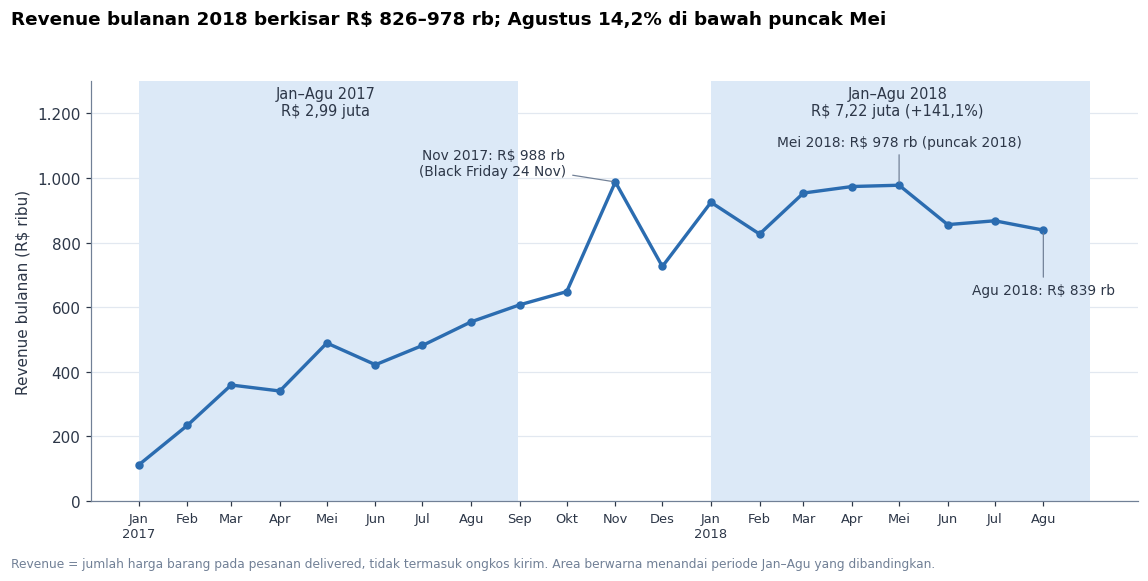

In [26]:
rev_ribu = bulanan["revenue"] / 1e3
rev_ribu.index = rev_ribu.index.to_timestamp()
rev_2018_ribu = rev_ribu[rev_ribu.index.year == 2018]
nama_puncak = BULAN_ID[bulan_puncak_2018.month - 1]
turun_dari_puncak = (rev_2018_ribu.iloc[-1] / rev_2018_ribu.max() - 1) * 100

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for awal, akhir in [("2017-01-01", "2017-08-31"), ("2018-01-01", "2018-08-31")]:
    ax.axvspan(pd.Timestamp(awal), pd.Timestamp(akhir), color="#DCE9F7", lw=0)
ax.plot(rev_ribu.index, rev_ribu, color=BIRU, marker="o", lw=2.2, ms=4.5, zorder=3)
ax.set_ylim(0, 1300)
ax.yaxis.set_major_formatter(format_sumbu(0))
ax.grid(axis="y")
ax.set_ylabel("Revenue bulanan (R$ ribu)")

# Label dua periode yang dibandingkan
rev_jan_agu = yoy["revenue"] / 1e6
ax.text(pd.Timestamp("2017-04-30"), 1285, f"Jan–Agu 2017\nR$ {angka(rev_jan_agu[2017], 2)} juta",
        ha="center", va="top", fontsize=9.5, color=GELAP)
ax.text(pd.Timestamp("2018-04-30"), 1285,
        f"Jan–Agu 2018\nR$ {angka(rev_jan_agu[2018], 2)} juta (+{angka(pertumbuhan_yoy['revenue'], 1)}%)",
        ha="center", va="top", fontsize=9.5, color=GELAP)

# Titik penting
garis_petunjuk = dict(arrowstyle="-", color="#718096", lw=0.8)
tgl_bf = pd.Timestamp("2017-11-01")
ax.annotate(f"Nov 2017: R$ {angka(rev_ribu[tgl_bf], 0)} rb\n(Black Friday 24 Nov)", xy=(tgl_bf, rev_ribu[tgl_bf]),
            xytext=(pd.Timestamp("2017-08-15"), 1010), fontsize=9, color=GELAP, ha="center", arrowprops=garis_petunjuk)
tgl_puncak = bulan_puncak_2018.to_timestamp()
ax.annotate(f"{nama_puncak} 2018: R$ {angka(rev_ribu[tgl_puncak], 0)} rb (puncak 2018)", xy=(tgl_puncak, rev_ribu[tgl_puncak]),
            xytext=(tgl_puncak, 1100), fontsize=9, color=GELAP, ha="center", arrowprops=garis_petunjuk)
tgl_akhir = rev_ribu.index[-1]
ax.annotate(f"Agu 2018: R$ {angka(rev_ribu.iloc[-1], 0)} rb", xy=(tgl_akhir, rev_ribu.iloc[-1]),
            xytext=(tgl_akhir, 640), fontsize=9, color=GELAP, ha="center", arrowprops=garis_petunjuk)

ax.set_xticks(rev_ribu.index)
ax.set_xticklabels(label_bulan(rev_ribu.index), fontsize=8.5)
judul_gambar(fig, f"Revenue bulanan 2018 berkisar R$ {angka(rev_2018_ribu.min(), 0)}–{angka(rev_2018_ribu.max(), 0)} rb; "
                  f"Agustus {angka(abs(turun_dari_puncak), 1)}% di bawah puncak {nama_puncak}")
catatan_kaki(fig, "Revenue = jumlah harga barang pada pesanan delivered, tidak termasuk ongkos kirim. Area berwarna menandai periode Jan–Agu yang dibandingkan.")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

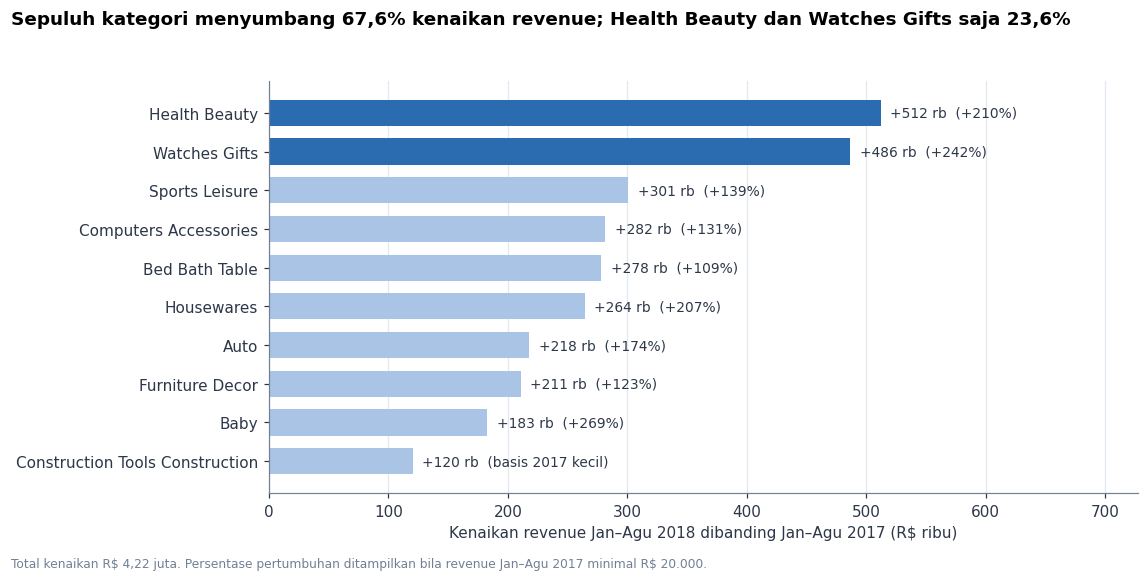

In [27]:
top_naik = kategori_yoy.sort_values("kenaikan", ascending=False).head(10).iloc[::-1]
total_kenaikan = kategori_yoy["kenaikan"].sum()
kontribusi_top10 = top_naik["kenaikan"].sum() / total_kenaikan * 100
kontribusi_top2 = top_naik.iloc[-2:]["kenaikan"].sum() / total_kenaikan * 100
dua_teratas = [nama_kategori(k) for k in top_naik.index[-2:][::-1]]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
warna = [BIRU if i >= len(top_naik) - 2 else BIRU_MUDA for i in range(len(top_naik))]
ax.barh([nama_kategori(k) for k in top_naik.index], top_naik["kenaikan"] / 1e3, color=warna, height=0.68)
ax.set_xlim(0, top_naik["kenaikan"].max() / 1e3 * 1.42)
ax.xaxis.set_major_formatter(format_sumbu(0))
ax.grid(axis="x")
ax.set_xlabel("Kenaikan revenue Jan–Agu 2018 dibanding Jan–Agu 2017 (R$ ribu)")

for posisi, (_, baris) in enumerate(top_naik.iterrows()):
    pertumbuhan = baris["pertumbuhan_pct"]
    teks_tumbuh = f"+{angka(pertumbuhan, 0)}%" if pd.notna(pertumbuhan) else "basis 2017 kecil"
    ax.text(baris["kenaikan"] / 1e3 + 8, posisi, f"+{angka(baris['kenaikan'] / 1e3, 0)} rb  ({teks_tumbuh})",
            va="center", fontsize=9, color=GELAP)

judul_gambar(fig, f"Sepuluh kategori menyumbang {angka(kontribusi_top10, 1)}% kenaikan revenue; "
                  f"{dua_teratas[0]} dan {dua_teratas[1]} saja {angka(kontribusi_top2, 1)}%")
catatan_kaki(fig, f"Total kenaikan R$ {angka(total_kenaikan / 1e6, 2)} juta. "
                  f"Persentase pertumbuhan ditampilkan bila revenue Jan–Agu 2017 minimal R$ {angka(BASIS_MINIMAL)}.")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

**Insight Pertanyaan 1:**
- Revenue Januari-Agustus 2018 tumbuh 141,1% dan jumlah pesanan tumbuh 139,9% dibandingkan periode yang sama pada 2017, sedangkan nilai per pesanan relatif tetap. Pertumbuhan berasal dari bertambahnya pesanan.
- Health Beauty dan Watches Gifts menyumbang 23,6% dari total kenaikan revenue, dan sepuluh kategori teratas 67,6%. Kategori peringkat ketiga sampai kesepuluh masing-masing menyumbang 2,8%-7,1%, sehingga kenaikan tersebar pada banyak kategori dan tidak bergantung pada satu kategori.
- Revenue bulanan 2018 tidak lagi naik: berkisar R$ 826-978 ribu per bulan, dan Agustus berada 14,2% di bawah puncak Mei. Pertumbuhan year-over-year yang tinggi sebagian besar mencerminkan basis 2017 yang rendah dan tidak menunjukkan percepatan pada 2018.

### Pertanyaan 2: Hubungan ketepatan waktu pengiriman dengan review score dan sebarannya per negara bagian

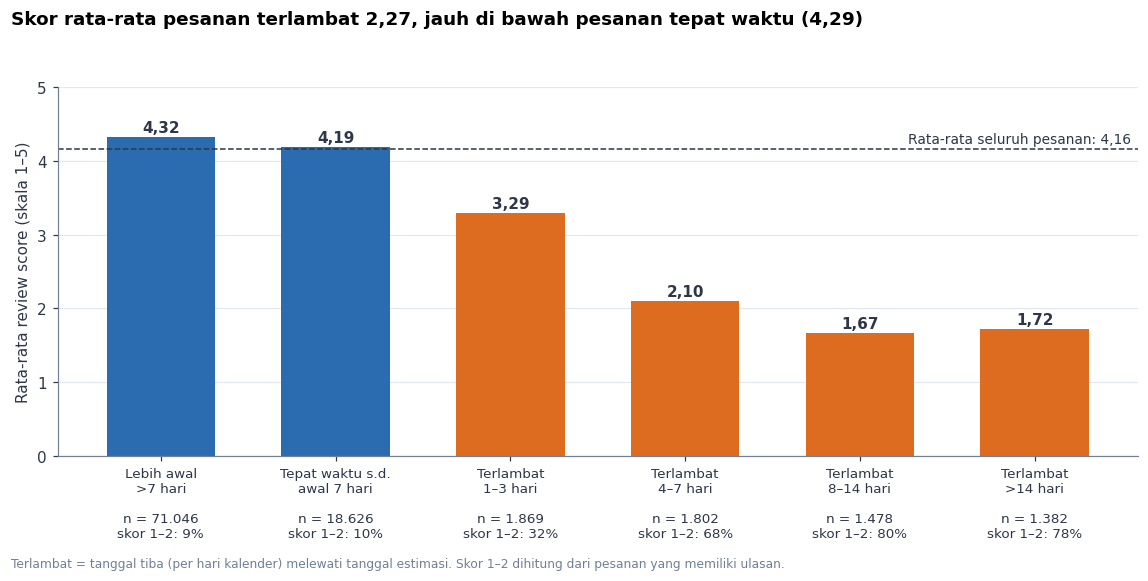

In [28]:
rata_review_semua = pesanan["review_score"].mean()
rata_tepat = per_status.loc["Tepat waktu", "rata_review"]
rata_telat = per_status.loc["Terlambat", "rata_review"]
label_dua_baris = {
    "Lebih awal >7 hari": "Lebih awal\n>7 hari",
    "Tepat waktu / awal ≤7 hari": "Tepat waktu s.d.\nawal 7 hari",
    "Terlambat 1–3 hari": "Terlambat\n1–3 hari",
    "Terlambat 4–7 hari": "Terlambat\n4–7 hari",
    "Terlambat 8–14 hari": "Terlambat\n8–14 hari",
    "Terlambat >14 hari": "Terlambat\n>14 hari",
}

fig, ax = plt.subplots(figsize=(10.5, 5.2))
posisi_x = np.arange(len(per_kelompok))
warna = [BIRU if "Terlambat" not in label else ORANYE for label in per_kelompok.index]
ax.bar(posisi_x, per_kelompok["rata_review"], color=warna, width=0.62)
ax.set_ylim(0, 5)
ax.set_ylabel("Rata-rata review score (skala 1–5)")
ax.grid(axis="y")
ax.axhline(rata_review_semua, color=GELAP, ls="--", lw=1)
ax.text(len(per_kelompok) - 0.45, rata_review_semua + 0.08, f"Rata-rata seluruh pesanan: {angka(rata_review_semua, 2)}",
        ha="right", fontsize=9, color=GELAP)
for x, (_, baris) in zip(posisi_x, per_kelompok.iterrows()):
    ax.text(x, baris["rata_review"] + 0.07, angka(baris["rata_review"], 2), ha="center", fontsize=10, fontweight="bold", color=GELAP)

ax.set_xticks(posisi_x)
ax.set_xticklabels([
    f"{label_dua_baris[label]}\n\nn = {angka(baris['pesanan'])}\nskor 1–2: {angka(baris['persen_review_1_2'], 0)}%"
    for label, (_, baris) in zip(per_kelompok.index, per_kelompok.iterrows())
], fontsize=8.8)
judul_gambar(fig, f"Skor rata-rata pesanan terlambat {angka(rata_telat, 2)}, jauh di bawah pesanan tepat waktu ({angka(rata_tepat, 2)})")
catatan_kaki(fig, "Terlambat = tanggal tiba (per hari kalender) melewati tanggal estimasi. Skor 1–2 dihitung dari pesanan yang memiliki ulasan.")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

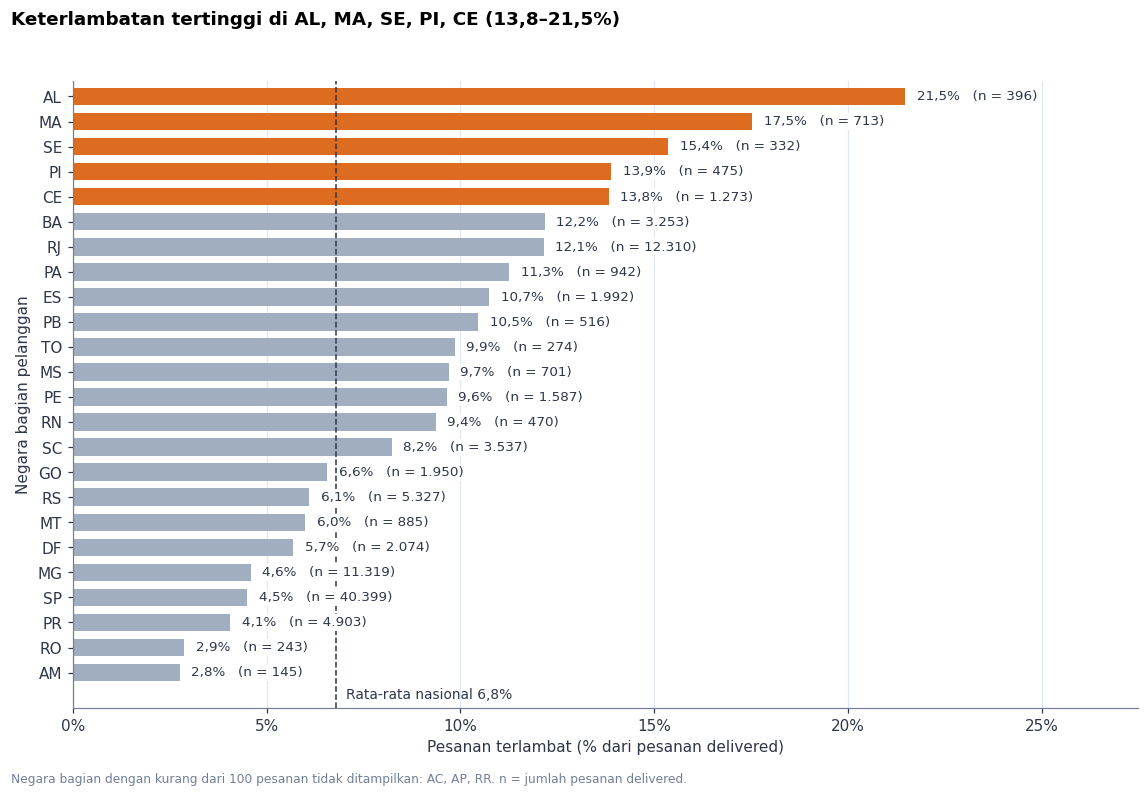

In [29]:
state_dibandingkan = per_state[per_state["pesanan"] >= MIN_PESANAN_STATE].sort_values("terlambat_pct")
state_diabaikan = per_state[per_state["pesanan"] < MIN_PESANAN_STATE].index.tolist()
rata_nasional_telat = pesanan["is_late"].mean() * 100
lima_tertinggi = state_dibandingkan.index[-5:]

fig, ax = plt.subplots(figsize=(10.5, 7.2))
warna = [ORANYE if s in lima_tertinggi else ABU for s in state_dibandingkan.index]
ax.barh(state_dibandingkan.index, state_dibandingkan["terlambat_pct"], color=warna, height=0.7, zorder=2)
ax.axvline(rata_nasional_telat, color=GELAP, ls="--", lw=1, zorder=3)
ax.text(rata_nasional_telat + 0.25, -0.9, f"Rata-rata nasional {angka(rata_nasional_telat, 1)}%", fontsize=9, color=GELAP, va="center")
ax.set_xlim(0, state_dibandingkan["terlambat_pct"].max() * 1.28)
ax.set_ylim(-1.4, len(state_dibandingkan) - 0.4)
ax.xaxis.set_major_formatter(format_persen(0))
ax.grid(axis="x")
ax.set_xlabel("Pesanan terlambat (% dari pesanan delivered)")
ax.set_ylabel("Negara bagian pelanggan")

for posisi, (_, baris) in enumerate(state_dibandingkan.iterrows()):
    ax.text(baris["terlambat_pct"] + 0.3, posisi, f"{angka(baris['terlambat_pct'], 1)}%   (n = {angka(baris['pesanan'])})",
            va="center", fontsize=8.8, color=GELAP, zorder=4, bbox=dict(facecolor="white", edgecolor="none", pad=1.2))

kisaran = state_dibandingkan.loc[lima_tertinggi, "terlambat_pct"]
judul_gambar(fig, f"Keterlambatan tertinggi di {', '.join(lima_tertinggi[::-1])} ({angka(kisaran.min(), 1)}–{angka(kisaran.max(), 1)}%)")
catatan_kaki(fig, f"Negara bagian dengan kurang dari {MIN_PESANAN_STATE} pesanan tidak ditampilkan: {', '.join(state_diabaikan)}. n = jumlah pesanan delivered.")
fig.tight_layout(rect=(0, 0.025, 1, 0.96))
plt.show()

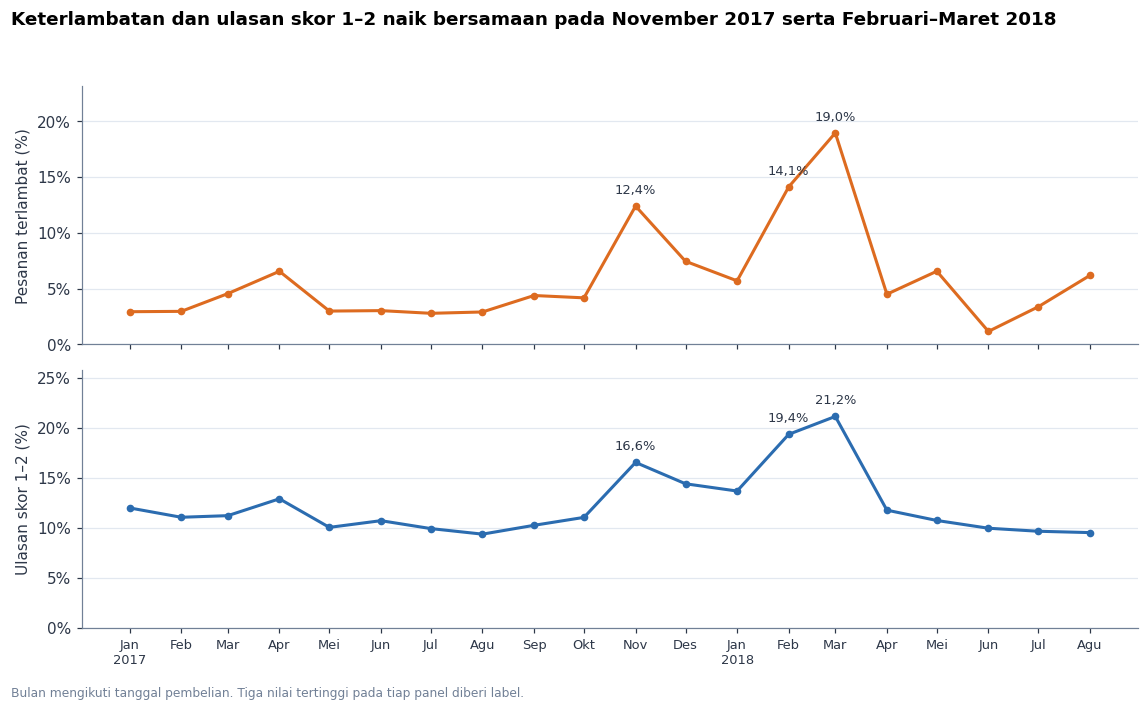

In [30]:
kirim_plot = kirim_bulanan.copy()
kirim_plot.index = kirim_plot.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True)
for ax, kolom, warna, label in [(ax1, "terlambat_pct", ORANYE, "Pesanan terlambat (%)"),
                                (ax2, "review_1_2_pct", BIRU, "Ulasan skor 1–2 (%)")]:
    ax.plot(kirim_plot.index, kirim_plot[kolom], color=warna, marker="o", lw=2, ms=4)
    ax.set_ylim(0, kirim_plot[kolom].max() * 1.22)
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(format_persen(0))
    ax.grid(axis="y")
    for tanggal in kirim_plot[kolom].nlargest(3).index:
        ax.annotate(f"{angka(kirim_plot.loc[tanggal, kolom], 1)}%", xy=(tanggal, kirim_plot.loc[tanggal, kolom]),
                    xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5, color=GELAP)

ax2.set_xticks(kirim_plot.index)
ax2.set_xticklabels(label_bulan(kirim_plot.index), fontsize=8.5)
judul_gambar(fig, "Keterlambatan dan ulasan skor 1–2 naik bersamaan pada November 2017 serta Februari–Maret 2018")
catatan_kaki(fig, "Bulan mengikuti tanggal pembelian. Tiga nilai tertinggi pada tiap panel diberi label.")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

**Insight Pertanyaan 2:**
- Review score rata-rata pesanan terlambat 2,27, sedangkan pesanan tepat waktu 4,29: selisih 2,02 poin. Ulasan 1-2 bintang mencapai 62,4% pada pesanan terlambat dibandingkan 9,2% pada pesanan tepat waktu. Skor sudah turun ke 3,29 pada keterlambatan 1-3 hari dan menjadi 2,10 pada 4-7 hari; keterlambatan yang lebih lama tidak memperbaikinya.
- Persentase pesanan terlambat nasional 6,8%. Tertinggi di AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), CE (13,8%), seluruhnya berada di wilayah timur laut. RJ (12,1%, sekitar 1,8 kali rata-rata nasional) dan BA (12,2%) juga tinggi. Dengan 12,8% dari seluruh pesanan, RJ menyumbang 22,9% dari seluruh pesanan terlambat.
- Keterlambatan memburuk pada periode tertentu, yaitu November 2017, Februari 2018, dan Maret 2018 (12,4%, 14,1%, 19,0%). Pada bulan yang sama persentase ulasan 1-2 bintang ikut naik.

## Analisis Lanjutan

Tiga teknik analisis lanjutan diterapkan tanpa algoritma machine learning. Tujuan masing-masing:

- **RFM analysis dan manual grouping** mengelompokkan pelanggan berdasarkan recency (hari sejak pembelian terakhir), frequency (jumlah pesanan), dan monetary (total belanja) untuk menjawab Pertanyaan 3. Karena 97% pelanggan hanya membeli satu kali, frequency tidak dapat dibagi menjadi skor lima tingkat berbasis kuantil (hampir semua pelanggan akan bernilai sama). Segmen karena itu dibentuk dengan aturan bisnis eksplisit.
- **Geospatial analysis** memetakan sebaran pesanan dan keterlambatan per negara bagian, serta menghitung jarak garis lurus antara zip prefix penjual dan pelanggan. Tujuannya memperdalam Pertanyaan 2: apakah jarak menjelaskan perbedaan keterlambatan antarwilayah.
- **Binning** mengelompokkan jarak pengiriman ke dalam lima rentang (keterlambatan sudah dikelompokkan ke dalam enam rentang pada Pertanyaan 2) agar hubungannya dengan durasi, keterlambatan, dan review dapat dibaca per kelompok.

### RFM Analysis dan Manual Grouping (menjawab Pertanyaan 3)

**Definisi RFM pada analisis ini**
- *Recency*: jumlah hari antara 1 September 2018 dan tanggal pembelian terakhir pelanggan.
- *Frequency*: jumlah pesanan valid per pelanggan selama periode analisis.
- *Monetary*: total `price` seluruh pesanan valid pelanggan (R$).

**Aturan segmentasi**

| Segmen | Aturan |
|---|---|
| Loyal - Aktif | frequency 2 atau lebih, recency 180 hari atau kurang |
| Loyal - Tidak Aktif | frequency 2 atau lebih, recency lebih dari 180 hari |
| Baru - Nilai Tinggi | frequency 1, recency 180 hari atau kurang, monetary di persentil ke-80 atau lebih |
| Baru - Reguler | frequency 1, recency 180 hari atau kurang, monetary di bawah persentil ke-80 |
| Dormant - Nilai Tinggi | frequency 1, recency lebih dari 180 hari, monetary di persentil ke-80 atau lebih |
| Dormant - Reguler | frequency 1, recency lebih dari 180 hari, monetary di bawah persentil ke-80 |

Batas 180 hari (sekitar enam bulan tanpa transaksi) dan persentil ke-80 pengeluaran adalah keputusan bisnis yang dapat disesuaikan. Pada dashboard, aturan yang sama diterapkan pada `main_data.csv`.

In [31]:
def hitung_rfm(data, tanggal_acuan):
    """RFM per pelanggan dari data berbaris item pesanan."""
    rfm = data.groupby("customer_unique_id").agg(
        pembelian_terakhir=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("price", "sum"),
    )
    rfm["recency"] = (tanggal_acuan - rfm["pembelian_terakhir"].dt.normalize()).dt.days
    rfm["monetary"] = rfm["monetary"].round(2)
    return rfm[["recency", "frequency", "monetary"]]


URUTAN_SEGMEN = ["Loyal - Aktif", "Loyal - Tidak Aktif", "Baru - Nilai Tinggi", "Baru - Reguler",
                 "Dormant - Nilai Tinggi", "Dormant - Reguler"]


def segmentasi_rfm(rfm, batas_recency, batas_monetary):
    """Pengelompokan manual berdasarkan aturan bisnis (tanpa algoritma machine learning)."""
    aktif = rfm["recency"] <= batas_recency
    bernilai_tinggi = rfm["monetary"] >= batas_monetary
    repeat = rfm["frequency"] >= 2
    return pd.Series(np.select(
        [repeat & aktif, repeat & ~aktif, ~repeat & aktif & bernilai_tinggi, ~repeat & aktif, ~repeat & bernilai_tinggi],
        URUTAN_SEGMEN[:5],
        default=URUTAN_SEGMEN[5],
    ), index=rfm.index, name="segmen")


BATAS_RECENCY_HARI = 180
rfm = hitung_rfm(main_df, TANGGAL_ACUAN_RFM)
BATAS_MONETARY = round(float(rfm["monetary"].quantile(0.80)), 2)
rfm["segmen"] = segmentasi_rfm(rfm, BATAS_RECENCY_HARI, BATAS_MONETARY)

print(f"Tanggal acuan recency        : {TANGGAL_ACUAN_RFM:%d %B %Y}")
print(f"Batas pelanggan aktif        : recency <= {BATAS_RECENCY_HARI} hari")
print(f"Batas nilai tinggi (P80)     : monetary >= R$ {BATAS_MONETARY:,.2f}")
print(f"Pelanggan dianalisis         : {len(rfm):,}")
display(rfm[["recency", "frequency", "monetary"]].describe(percentiles=[0.2, 0.5, 0.8, 0.95]).T)

ringkasan_segmen = rfm.groupby("segmen").agg(
    pelanggan=("frequency", "size"),
    revenue=("monetary", "sum"),
    rata_pengeluaran=("monetary", "mean"),
    median_recency=("recency", "median"),
    rata_frekuensi=("frequency", "mean"),
).reindex(URUTAN_SEGMEN)
ringkasan_segmen["pelanggan_pct"] = ringkasan_segmen["pelanggan"] / ringkasan_segmen["pelanggan"].sum() * 100
ringkasan_segmen["revenue_pct"] = ringkasan_segmen["revenue"] / ringkasan_segmen["revenue"].sum() * 100
display(ringkasan_segmen)

pengeluaran_tinggi = rfm["monetary"] >= BATAS_MONETARY
print(f"Pelanggan dengan pengeluaran >= P80: {pengeluaran_tinggi.mean():.1%} dari pelanggan, "
      f"{rfm.loc[pengeluaran_tinggi, 'monetary'].sum() / rfm['monetary'].sum():.1%} dari revenue")
print(f"Pelanggan repeat (frekuensi >= 2): {(rfm['frequency'] >= 2).mean():.2%} dari pelanggan, "
      f"{rfm.loc[rfm['frequency'] >= 2, 'monetary'].sum() / rfm['monetary'].sum():.1%} dari revenue")

Tanggal acuan recency        : 01 September 2018
Batas pelanggan aktif        : recency <= 180 hari
Batas nilai tinggi (P80)     : monetary >= R$ 179.90
Pelanggan dianalisis         : 93,096


,count,mean,std,min,20%,50%,80%,95%,max
recency,"93,096.00",239.25,150.94,3.00,94.00,221.00,383.00,519.00,604.00
frequency,"93,096.00",1.03,0.21,1.00,1.00,1.00,1.00,1.00,15.00
monetary,"93,096.00",141.57,215.77,0.85,39.90,89.70,179.90,419.45,"13,440.00"


,pelanggan,revenue,rata_pengeluaran,median_recency,rata_frekuensi,pelanggan_pct,revenue_pct
segmen,,,,,,,
Loyal - Aktif,1210,"326,871.89",270.14,92.00,2.15,1.30,2.48
Loyal - Tidak Aktif,1579,"398,483.15",252.36,298.00,2.08,1.70,3.02
Baru - Nilai Tinggi,6999,"2,842,714.36",406.16,97.00,1.00,7.52,21.57
Baru - Reguler,29344,"2,258,530.15",76.97,95.00,1.00,31.52,17.14
Dormant - Nilai Tinggi,10311,"4,064,090.27",394.15,319.00,1.00,11.08,30.84
Dormant - Reguler,43653,"3,289,088.13",75.35,314.00,1.00,46.89,24.96


Pelanggan dengan pengeluaran >= P80: 20.1% dari pelanggan, 56.8% dari revenue
Pelanggan repeat (frekuensi >= 2): 3.00% dari pelanggan, 5.5% dari revenue


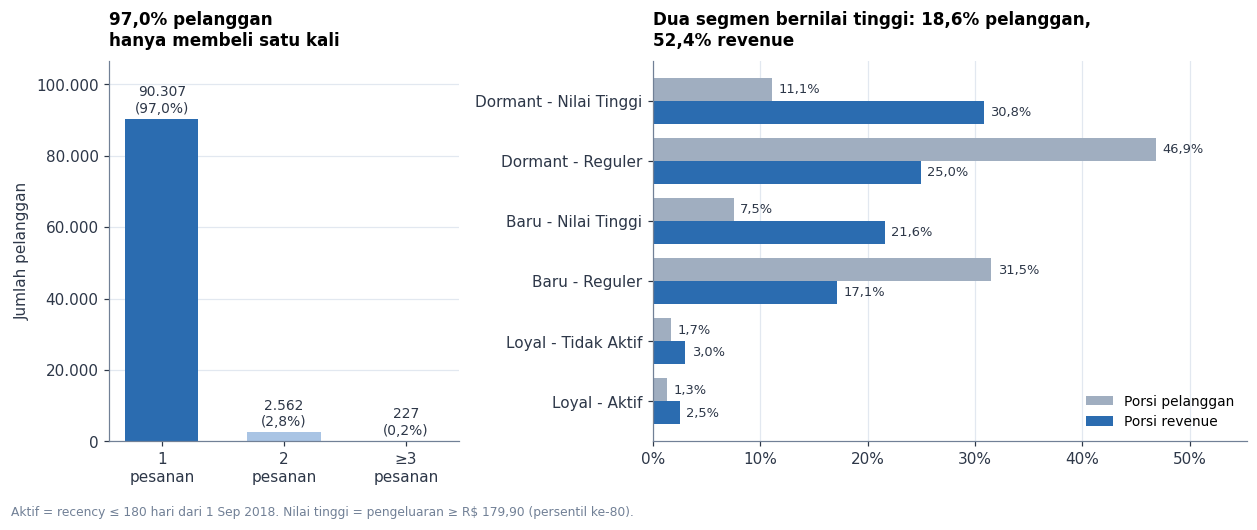

In [32]:
segmen_bernilai_tinggi = ringkasan_segmen[ringkasan_segmen.index.str.contains("Nilai Tinggi")]
pelanggan_tinggi_pct = segmen_bernilai_tinggi["pelanggan_pct"].sum()
revenue_tinggi_pct = segmen_bernilai_tinggi["revenue_pct"].sum()
pelanggan_sekali_pct = distribusi_frekuensi.iloc[0] / distribusi_frekuensi.sum() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})

# Panel kiri: distribusi jumlah pesanan per pelanggan
ax1.bar(distribusi_frekuensi.index, distribusi_frekuensi.values, color=[BIRU, BIRU_MUDA, BIRU_MUDA], width=0.6)
ax1.set_ylim(0, distribusi_frekuensi.max() * 1.18)
ax1.yaxis.set_major_formatter(format_sumbu(0))
ax1.grid(axis="y")
ax1.set_ylabel("Jumlah pelanggan")
for x, nilai in enumerate(distribusi_frekuensi.values):
    ax1.text(x, nilai + distribusi_frekuensi.max() * 0.02,
             f"{angka(nilai)}\n({angka(nilai / distribusi_frekuensi.sum() * 100, 1)}%)", ha="center", fontsize=9, color=GELAP)
ax1.set_xticks(range(3))
ax1.set_xticklabels(["1\npesanan", "2\npesanan", "≥3\npesanan"])
ax1.set_title(f"{angka(pelanggan_sekali_pct, 1)}% pelanggan\nhanya membeli satu kali", fontsize=11)

# Panel kanan: porsi pelanggan dan porsi revenue per segmen
urut = ringkasan_segmen.sort_values("revenue_pct")
tinggi_bar = 0.38
posisi = np.arange(len(urut))
ax2.barh(posisi + tinggi_bar / 2, urut["pelanggan_pct"], height=tinggi_bar, color=ABU, label="Porsi pelanggan")
ax2.barh(posisi - tinggi_bar / 2, urut["revenue_pct"], height=tinggi_bar, color=BIRU, label="Porsi revenue")
for y, (_, baris) in zip(posisi, urut.iterrows()):
    ax2.text(baris["pelanggan_pct"] + 0.6, y + tinggi_bar / 2, f"{angka(baris['pelanggan_pct'], 1)}%", va="center", fontsize=8.5, color=GELAP)
    ax2.text(baris["revenue_pct"] + 0.6, y - tinggi_bar / 2, f"{angka(baris['revenue_pct'], 1)}%", va="center", fontsize=8.5, color=GELAP)
ax2.set_yticks(posisi)
ax2.set_yticklabels(urut.index)
ax2.set_xlim(0, max(urut["pelanggan_pct"].max(), urut["revenue_pct"].max()) * 1.18)
ax2.xaxis.set_major_formatter(format_persen(0))
ax2.grid(axis="x")
ax2.legend(frameon=False, loc="lower right", fontsize=9)
ax2.set_title(f"Dua segmen bernilai tinggi: {angka(pelanggan_tinggi_pct, 1)}% pelanggan,\n{angka(revenue_tinggi_pct, 1)}% revenue", fontsize=11)
catatan_kaki(fig, f"Aktif = recency ≤ {BATAS_RECENCY_HARI} hari dari 1 Sep 2018. Nilai tinggi = pengeluaran ≥ R$ {angka(BATAS_MONETARY, 2)} (persentil ke-80).")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

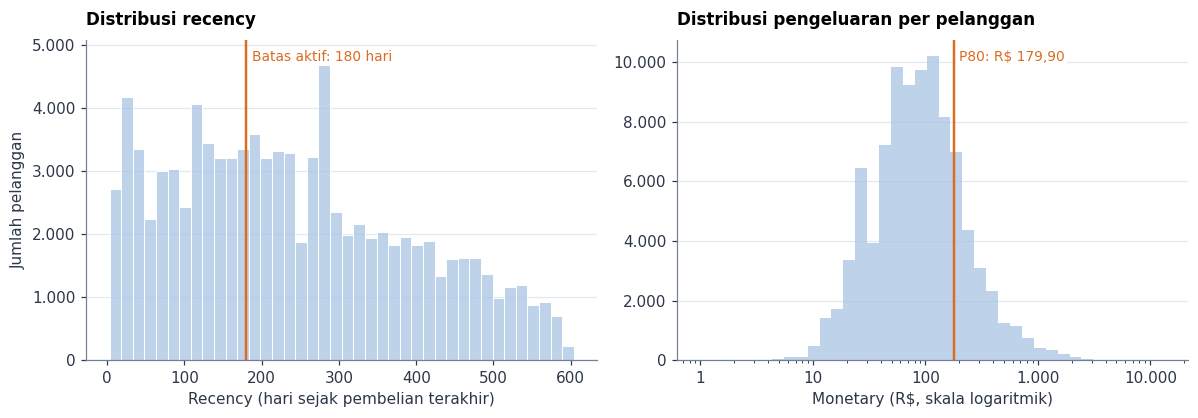

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9))
sns.histplot(rfm["recency"], bins=40, color=BIRU_MUDA, edgecolor="white", ax=ax1)
ax1.axvline(BATAS_RECENCY_HARI, color=ORANYE, lw=1.6)
ax1.text(BATAS_RECENCY_HARI + 8, ax1.get_ylim()[1] * 0.97, f"Batas aktif: {BATAS_RECENCY_HARI} hari", color=ORANYE,
         fontsize=9, va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax1.set_xlabel("Recency (hari sejak pembelian terakhir)")
ax1.set_ylabel("Jumlah pelanggan")
ax1.yaxis.set_major_formatter(format_sumbu(0))
ax1.set_title("Distribusi recency", fontsize=11)
ax1.grid(axis="y")

batas_log = np.logspace(np.log10(max(rfm["monetary"].min(), 1)), np.log10(rfm["monetary"].max()), 40)
sns.histplot(rfm["monetary"], bins=batas_log, color=BIRU_MUDA, edgecolor="white", ax=ax2)
ax2.set_xscale("log")
ax2.axvline(BATAS_MONETARY, color=ORANYE, lw=1.6)
ax2.text(BATAS_MONETARY * 1.1, ax2.get_ylim()[1] * 0.97, f"P80: R$ {angka(BATAS_MONETARY, 2)}", color=ORANYE,
         fontsize=9, va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax2.set_xlabel("Monetary (R$, skala logaritmik)")
ax2.set_ylabel("")
ax2.yaxis.set_major_formatter(format_sumbu(0))
ax2.xaxis.set_major_formatter(format_sumbu(0))
ax2.set_title("Distribusi pengeluaran per pelanggan", fontsize=11)
ax2.grid(axis="y")
fig.tight_layout()
plt.show()

#### Pengalaman pengiriman dan pembelian ulang

Pertanyaan 2 menunjukkan bahwa pesanan terlambat berasosiasi dengan review score yang lebih rendah. Untuk melihat apakah ketepatan waktu pesanan pertama juga berkaitan dengan pembelian ulang, pelanggan dikelompokkan menurut status keterlambatan pesanan pertama yang teramati dalam periode analisis. “Pesanan pertama” di bagian ini berarti pesanan pertama yang teramati dalam periode analisis valid (1 Januari 2017–31 Agustus 2018), bukan selalu pesanan pertama sepanjang riwayat pelanggan. Hanya pembelian yang dibuat setelah pesanan tersebut diterima yang dihitung. Kohort dibatasi pada pelanggan yang pesanan pertamanya dalam periode analisis sudah diterima paling lambat 180 hari sebelum tanggal acuan (1 September 2018), agar setiap pelanggan memiliki jendela pengamatan penuh yang sama. Karena itu, tingkat beli ulang 1,82% berlaku untuk kohort yang memenuhi syarat ini, bukan untuk semua pelanggan tanpa batasan. Perbedaan kedua kelompok diuji dengan uji z dua proporsi.

In [34]:
# Pesanan pertama tiap pelanggan dan pembelian berikutnya yang dibuat setelah pesanan pertama diterima
urut_pesanan = pesanan.sort_values(["customer_unique_id", "order_purchase_timestamp"]).copy()
urut_pesanan["urutan"] = urut_pesanan.groupby("customer_unique_id").cumcount() + 1

pertama = urut_pesanan.loc[urut_pesanan["urutan"] == 1,
                           ["customer_unique_id", "order_delivered_customer_date", "is_late"]].rename(
    columns={"order_delivered_customer_date": "tiba_pertama"})
lanjutan = urut_pesanan.loc[urut_pesanan["urutan"] > 1, ["customer_unique_id", "order_purchase_timestamp"]].merge(
    pertama[["customer_unique_id", "tiba_pertama"]], on="customer_unique_id")
lanjutan = lanjutan[lanjutan["order_purchase_timestamp"] > lanjutan["tiba_pertama"]]
pembelian_berikut = lanjutan.groupby("customer_unique_id")["order_purchase_timestamp"].min().rename("pembelian_berikut")

kohort = pertama.merge(pembelian_berikut, on="customer_unique_id", how="left")
# Hanya pelanggan yang pesanan pertamanya sudah diterima >= 180 hari sebelum tanggal acuan, agar setiap pelanggan punya jendela pengamatan penuh
kohort = kohort[kohort["tiba_pertama"] <= TANGGAL_ACUAN_RFM - pd.Timedelta(days=180)].copy()
kohort["beli_lagi_180_hari"] = (kohort["pembelian_berikut"] - kohort["tiba_pertama"]) <= pd.Timedelta(days=180)

hasil_kohort = kohort.groupby("is_late").agg(pelanggan=("beli_lagi_180_hari", "size"), beli_lagi=("beli_lagi_180_hari", "sum"))
hasil_kohort["persen_beli_lagi"] = hasil_kohort["beli_lagi"] / hasil_kohort["pelanggan"] * 100
hasil_kohort.index = hasil_kohort.index.map({False: "Pesanan pertama tepat waktu", True: "Pesanan pertama terlambat"})
display(hasil_kohort)


def uji_dua_proporsi(k1, n1, k2, n2):
    """Uji z dua proporsi (dua sisi). Mengembalikan statistik z dan p-value."""
    p1, p2, gabungan = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    galat = math.sqrt(gabungan * (1 - gabungan) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / galat
    return z, math.erfc(abs(z) / math.sqrt(2))


tepat, telat = hasil_kohort.iloc[0], hasil_kohort.iloc[1]
z_hitung, p_nilai = uji_dua_proporsi(tepat["beli_lagi"], tepat["pelanggan"], telat["beli_lagi"], telat["pelanggan"])
selisih_pp = tepat["persen_beli_lagi"] - telat["persen_beli_lagi"]
print(f"Pelanggan dalam kohort                 : {len(kohort):,}")
print(f"Selisih tingkat beli ulang             : {selisih_pp:.2f} poin persentase (tepat waktu - terlambat)")
print(f"Uji z dua proporsi                     : z = {z_hitung:.2f}, p = {p_nilai:.3f}")

# Waktu pembelian ulang: berapa hari setelah pesanan pertama diterima (hanya yang kembali dalam 180 hari)
jeda_beli_lagi = (kohort["pembelian_berikut"] - kohort["tiba_pertama"]).dt.days[kohort["beli_lagi_180_hari"]]
print(f"\nPelanggan yang membeli lagi dalam 180 hari   : {len(jeda_beli_lagi):,} ({len(jeda_beli_lagi) / len(kohort):.2%} dari kohort)")
print(f"Jeda median setelah pesanan pertama diterima : {jeda_beli_lagi.median():.0f} hari")
print(f"Pembelian ulang dalam 30 hari pertama        : {(jeda_beli_lagi <= 30).mean():.1%}")
print(f"Pembelian ulang dalam 90 hari pertama        : {(jeda_beli_lagi <= 90).mean():.1%}")

,pelanggan,beli_lagi,persen_beli_lagi
is_late,,,
Pesanan pertama tepat waktu,49676,915,1.84
Pesanan pertama terlambat,2671,36,1.35


Pelanggan dalam kohort                 : 52,347
Selisih tingkat beli ulang             : 0.49 poin persentase (tepat waktu - terlambat)
Uji z dua proporsi                     : z = 1.86, p = 0.063

Pelanggan yang membeli lagi dalam 180 hari   : 951 (1.82% dari kohort)
Jeda median setelah pesanan pertama diterima : 61 hari
Pembelian ulang dalam 30 hari pertama        : 31.2%
Pembelian ulang dalam 90 hari pertama        : 63.7%


**Insight (RFM):**
- Hanya 3,00% pelanggan (2.789) yang membeli lebih dari satu kali, dan mereka menyumbang 5,5% revenue. 784 di antaranya membeli seluruh pesanannya pada hari yang sama; pelanggan yang benar-benar kembali pada tanggal berbeda hanya 2,15%.
- Segmen terbesar adalah Dormant - Reguler (46,9% pelanggan, 25,0% revenue). Dua segmen bernilai tinggi (Baru dan Dormant) hanya mencakup 18,6% pelanggan tetapi menyumbang 52,4% revenue; rata-rata belanja mereka R$ 399 per pelanggan, berbanding R$ 76 pada dua segmen reguler.
- Baru - Nilai Tinggi (6.999 pelanggan, R$ 2,84 juta) adalah sasaran kampanye pembelian kedua yang paling mendesak: pembelian terakhirnya masih dalam 180 hari dan nilainya tinggi. Dormant - Nilai Tinggi (10.311 pelanggan, R$ 4,06 juta) adalah sasaran win-back dengan potensi revenue terbesar.
- Pada 52.347 pelanggan yang diamati, tingkat pembelian ulang dalam 180 hari setelah pesanan pertama diterima adalah 1,82%. Angkanya 1,84% bila pesanan pertama tepat waktu dan 1,35% bila terlambat (selisih 0,49 poin persentase, uji z p = 0,063). Perbedaan ini searah dengan asosiasi antara keterlambatan dan review score, tetapi belum signifikan pada tingkat 5%; hasil ini bersifat indikatif dan tidak membuktikan hubungan sebab-akibat.
- Dari pelanggan yang membeli lagi dalam 180 hari, 31% melakukannya dalam 30 hari pertama dan 64% dalam 90 hari pertama (median 61 hari setelah pesanan diterima).

### Geospatial Analysis dan Binning Jarak (memperdalam Pertanyaan 2)

Koordinat zip prefix dipakai untuk dua hal. Pertama, memetakan jumlah pesanan dan persentase keterlambatan per negara bagian. Kedua, menghitung jarak garis lurus (haversine) antara penjual dan pelanggan, lalu mengelompokkannya ke dalam lima rentang jarak. Pada pesanan multi-penjual dipakai jarak terjauh. Jarak garis lurus adalah pendekatan; panjang rute sebenarnya lebih besar.

In [35]:
# Titik pusat tiap negara bagian = median koordinat zip prefix pelanggan
pusat_state = pesanan.groupby("customer_state")[["customer_lat", "customer_lng"]].median()
peta_state = per_state.join(pusat_state)
titik_zip_pelanggan = pesanan[["customer_lat", "customer_lng"]].dropna().drop_duplicates()
print(f"Titik zip prefix pelanggan unik : {len(titik_zip_pelanggan):,}")
print(f"Negara bagian pada peta         : {len(peta_state)} (dengan koordinat: {peta_state['customer_lat'].notna().sum()})")

# Binning jarak penjual ke pelanggan (km)
BATAS_JARAK = [-0.1, 100, 500, 1000, 2000, np.inf]
LABEL_JARAK = ["≤100 km", "101–500 km", "501–1.000 km", "1.001–2.000 km", ">2.000 km"]
pesanan["kelompok_jarak"] = pd.cut(pesanan["distance_km"], bins=BATAS_JARAK, labels=LABEL_JARAK)
per_jarak = pesanan.groupby("kelompok_jarak", observed=True).agg(
    pesanan=("order_id", "size"),
    rata_durasi_hari=("delivery_days", "mean"),
    median_durasi_hari=("delivery_days", "median"),
    terlambat_pct=("is_late", lambda s: s.mean() * 100),
    rata_review=("review_score", "mean"),
)
display(per_jarak)

korelasi_jarak = pesanan[["distance_km", "delivery_days"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman jarak vs durasi pengiriman: {korelasi_jarak:.3f}")
print(f"Pesanan tanpa data jarak (dikeluarkan dari analisis jarak): {pesanan['distance_km'].isna().sum():,}")

# Apakah jarak atau estimasi pengiriman yang menjelaskan perbedaan keterlambatan antar negara bagian?
pesanan["estimasi_hari"] = (
    pesanan["order_estimated_delivery_date"].dt.normalize() - pesanan["order_purchase_timestamp"].dt.normalize()
).dt.days
pesanan["tiba_hari"] = (
    pesanan["order_delivered_customer_date"].dt.normalize() - pesanan["order_purchase_timestamp"].dt.normalize()
).dt.days

median_state = pesanan.groupby("customer_state").agg(
    median_jarak_km=("distance_km", "median"),
    median_estimasi_hari=("estimasi_hari", "median"),
    median_tiba_hari=("tiba_hari", "median"),
)
median_state["selisih_estimasi_hari"] = median_state["median_estimasi_hari"] - median_state["median_tiba_hari"]
tabel_state = per_state[["pesanan", "terlambat_pct"]].join(median_state)
tabel_state = tabel_state[tabel_state["pesanan"] >= MIN_PESANAN_STATE]

korelasi_state_jarak = tabel_state[["median_jarak_km", "terlambat_pct"]].corr(method="spearman").iloc[0, 1]
korelasi_state_selisih = tabel_state[["selisih_estimasi_hari", "terlambat_pct"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman % terlambat vs median jarak               : {korelasi_state_jarak:+.2f} (n = {len(tabel_state)} negara bagian)")
print(f"Korelasi Spearman % terlambat vs selisih estimasi - aktual   : {korelasi_state_selisih:+.2f}")
print("\nNegara bagian dengan keterlambatan tertinggi dan terendah:")
tampil = tabel_state.sort_values("terlambat_pct", ascending=False)
display(pd.concat([tampil.head(6), tampil.tail(3)]))

Titik zip prefix pelanggan unik : 14,732
Negara bagian pada peta         : 27 (dengan koordinat: 27)


,pesanan,rata_durasi_hari,median_durasi_hari,terlambat_pct,rata_review
kelompok_jarak,,,,,
≤100 km,17757,6.48,5.08,4.49,4.28
101–500 km,36850,11.49,9.34,6.12,4.18
501–1.000 km,25771,14.27,12.12,7.11,4.11
1.001–2.000 km,9743,17.92,15.33,9.48,4.05
>2.000 km,5605,21.13,18.23,12.04,3.97


Korelasi Spearman jarak vs durasi pengiriman: 0.542
Pesanan tanpa data jarak (dikeluarkan dari analisis jarak): 477
Korelasi Spearman % terlambat vs median jarak               : +0.25 (n = 24 negara bagian)
Korelasi Spearman % terlambat vs selisih estimasi - aktual   : -0.54

Negara bagian dengan keterlambatan tertinggi dan terendah:


,pesanan,terlambat_pct,median_jarak_km,median_estimasi_hari,median_tiba_hari,selisih_estimasi_hari
customer_state,,,,,,
AL,396,21.46,"1,914.90",32.00,22.00,10.00
MA,713,17.53,"2,197.30",31.00,19.00,12.00
SE,332,15.36,"1,721.60",30.00,18.00,12.00
PI,475,13.89,"2,058.40",30.00,16.00,14.00
CE,1273,13.83,"2,292.45",32.00,18.00,14.00
BA,3253,12.17,"1,425.60",30.00,17.00,13.00
PR,4903,4.06,426.90,25.00,10.00,15.00
RO,243,2.88,"2,288.60",38.00,18.00,20.00
AM,145,2.76,"2,692.80",46.00,26.00,20.00


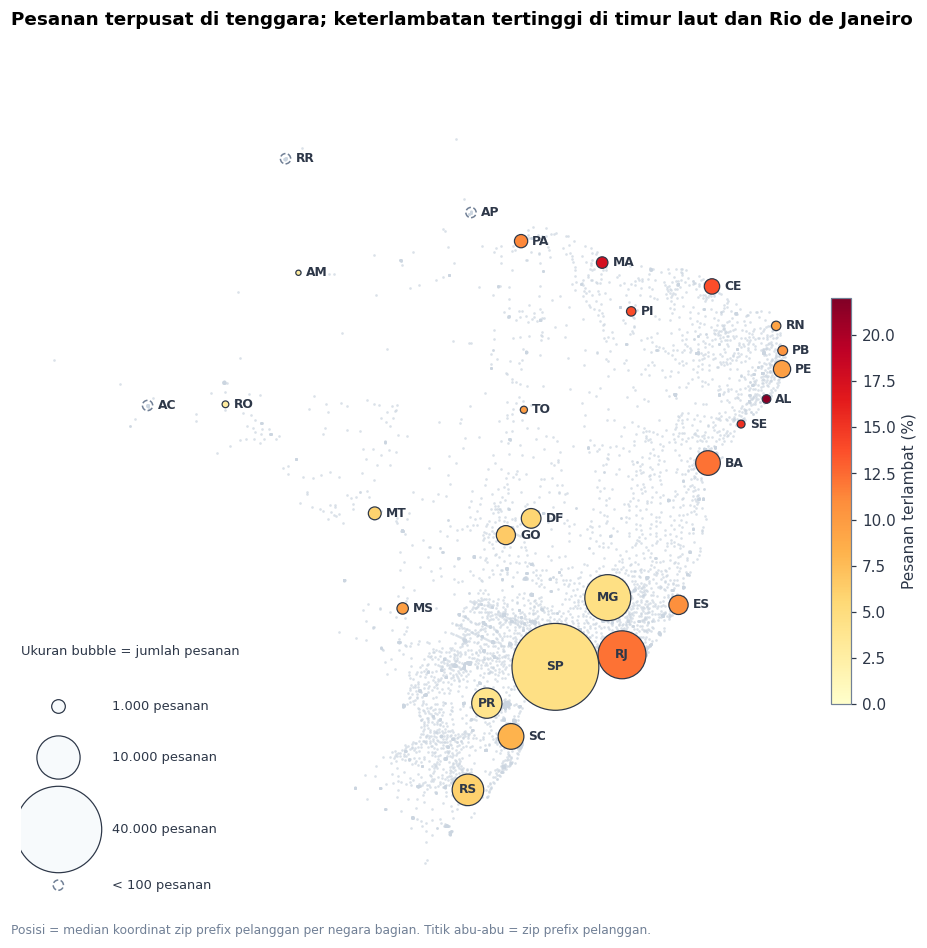

In [36]:
SKALA_BUBBLE = 0.08   # luas bubble (poin^2) per pesanan, sehingga luas sebanding dengan jumlah pesanan
PUNCAK_WARNA = 22

fig, ax = plt.subplots(figsize=(9, 8.6))
ax.scatter(titik_zip_pelanggan["customer_lng"], titik_zip_pelanggan["customer_lat"], s=3, color="#CBD5E0", alpha=0.7, lw=0, zorder=1)

cukup = peta_state[peta_state["pesanan"] >= MIN_PESANAN_STATE]
sedikit = peta_state[peta_state["pesanan"] < MIN_PESANAN_STATE]
sebar = ax.scatter(cukup["customer_lng"], cukup["customer_lat"], s=cukup["pesanan"] * SKALA_BUBBLE, c=cukup["terlambat_pct"],
                   cmap="YlOrRd", vmin=0, vmax=PUNCAK_WARNA, edgecolor=GELAP, linewidth=0.8, zorder=3)
ax.scatter(sedikit["customer_lng"], sedikit["customer_lat"], s=45, facecolor="none", edgecolor="#718096",
           linewidth=1, linestyle="--", zorder=2)

# Kode negara bagian: di dalam bubble jika cukup besar, selain itu di sebelah kanan bubble
for kode, baris in peta_state.iterrows():
    diameter = math.sqrt(baris["pesanan"] * SKALA_BUBBLE) if baris["pesanan"] >= MIN_PESANAN_STATE else 7
    if diameter >= 17:
        warna_teks = "white" if baris["terlambat_pct"] > 14 else GELAP
        ax.annotate(kode, (baris["customer_lng"], baris["customer_lat"]), ha="center", va="center",
                    fontsize=8, fontweight="bold", color=warna_teks, zorder=4)
    else:
        ax.annotate(kode, (baris["customer_lng"], baris["customer_lat"]), xytext=(diameter / 2 + 3, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=8, fontweight="bold", color=GELAP, zorder=4)

batang = fig.colorbar(sebar, ax=ax, shrink=0.5, pad=0.01)
batang.set_label("Pesanan terlambat (%)")
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
for sisi in ax.spines.values():
    sisi.set_visible(False)

judul_gambar(fig, "Pesanan terpusat di tenggara; keterlambatan tertinggi di timur laut dan Rio de Janeiro")
catatan_kaki(fig, "Posisi = median koordinat zip prefix pelanggan per negara bagian. Titik abu-abu = zip prefix pelanggan.")
fig.tight_layout(rect=(0, 0.02, 1, 0.95))

# Legenda ukuran bubble (dibuat manual agar lingkaran tidak menimpa teks); ditambahkan setelah tata letak diatur
legenda = fig.add_axes([0.02, 0.05, 0.27, 0.27])
legenda.set_xlim(0, 1)
legenda.set_ylim(0, 1)
legenda.axis("off")
legenda.text(0.0, 0.98, "Ukuran bubble = jumlah pesanan", fontsize=8.5, va="top", color=GELAP)
for y, contoh in zip([0.74, 0.54, 0.26], (1000, 10000, 40000)):
    legenda.scatter([0.14], [y], s=contoh * SKALA_BUBBLE, facecolor="#F7FAFC", edgecolor=GELAP, linewidth=0.8)
    legenda.text(0.34, y, f"{angka(contoh)} pesanan", va="center", fontsize=8.5, color=GELAP)
legenda.scatter([0.14], [0.04], s=45, facecolor="none", edgecolor="#718096", linewidth=1, linestyle="--")
legenda.text(0.34, 0.04, f"< {MIN_PESANAN_STATE} pesanan", va="center", fontsize=8.5, color=GELAP)

plt.show()

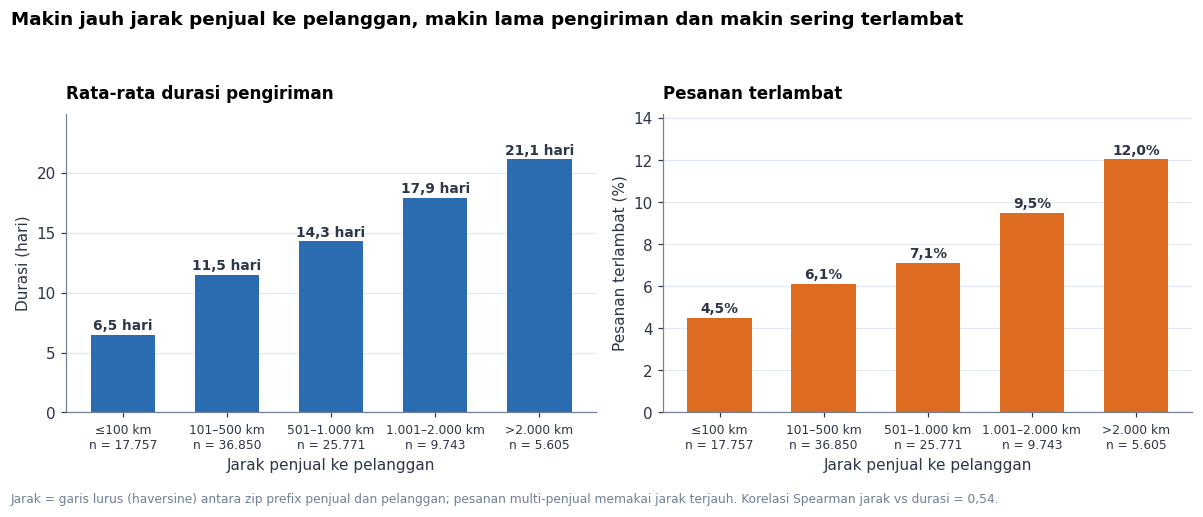

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
posisi_x = np.arange(len(per_jarak))
for ax, kolom, warna, judul, satuan in [
    (ax1, "rata_durasi_hari", BIRU, "Rata-rata durasi pengiriman", " hari"),
    (ax2, "terlambat_pct", ORANYE, "Pesanan terlambat", "%"),
]:
    ax.bar(posisi_x, per_jarak[kolom], color=warna, width=0.62)
    ax.set_ylim(0, per_jarak[kolom].max() * 1.18)
    ax.grid(axis="y")
    ax.set_xticks(posisi_x)
    ax.set_xticklabels([f"{label}\nn = {angka(n)}" for label, n in zip(per_jarak.index, per_jarak["pesanan"])], fontsize=8)
    ax.set_xlabel("Jarak penjual ke pelanggan")
    ax.set_title(judul, fontsize=11)
    for x, nilai in zip(posisi_x, per_jarak[kolom]):
        ax.text(x, nilai + per_jarak[kolom].max() * 0.02, f"{angka(nilai, 1)}{satuan}", ha="center", fontsize=9, fontweight="bold", color=GELAP)
ax1.set_ylabel("Durasi (hari)")
ax2.set_ylabel("Pesanan terlambat (%)")
judul_gambar(fig, "Makin jauh jarak penjual ke pelanggan, makin lama pengiriman dan makin sering terlambat")
catatan_kaki(fig, f"Jarak = garis lurus (haversine) antara zip prefix penjual dan pelanggan; pesanan multi-penjual memakai jarak terjauh. "
                  f"Korelasi Spearman jarak vs durasi = {angka(korelasi_jarak, 2)}.")
fig.tight_layout(rect=(0, 0.04, 1, 0.94))
plt.show()

**Insight (Geospatial dan Binning):**
- Pesanan terkonsentrasi di tenggara: SP, RJ, dan MG menyumbang 66,6% pesanan. Pasokan lebih terkonsentrasi lagi: 70,8% item dikirim dari SP, sehingga 64,3% pesanan melintasi batas negara bagian.
- Jarak berkaitan dengan durasi pengiriman (korelasi Spearman 0,54). Rata-rata durasi 6,5 hari untuk jarak 100 km atau kurang dan 21,1 hari untuk jarak di atas 2.000 km. Persentase terlambat naik dari 4,5% menjadi 12,0%, dan rata-rata review turun dari 4,28 menjadi 3,97.
- Jarak tidak menjelaskan perbedaan keterlambatan antarnegara bagian (korelasi Spearman 0,25 pada 24 negara bagian). RJ memiliki median jarak hanya 396 km tetapi 12,1% pesanannya terlambat, sedangkan AM dan RO berjarak lebih dari 2.000 km dengan persentase terlambat di bawah 3%.
- Yang lebih berkaitan dengan keterlambatan adalah selisih antara estimasi dan durasi aktual (median, dalam hari): korelasinya dengan persentase terlambat -0,54. Lima negara bagian dengan keterlambatan tertinggi hanya memiliki selisih 10-14 hari, sedangkan AM dan RO memiliki 20 hari. Sebagian perbedaan antarnegara bagian karena itu mencerminkan seberapa longgar estimasi ditetapkan, selain kecepatan pengiriman itu sendiri. Hubungan ini bersifat korelasi pada tingkat negara bagian dan belum membuktikan sebab-akibat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue Januari-Agustus 2018 sebesar R$ 7,22 juta, tumbuh 141,1% dari R$ 2,99 juta pada periode yang sama 2017. Jumlah pesanan tumbuh 139,9% sedangkan nilai per pesanan tetap (naik 0,5%), jadi pertumbuhan berasal dari volume pesanan. Health Beauty (+R$ 512 ribu) dan Watches Gifts (+R$ 486 ribu) menyumbang 23,6% dari total kenaikan, dan sepuluh kategori teratas 67,6%. Namun revenue bulanan 2018 tidak lagi naik: berkisar R$ 826-978 ribu, dengan Agustus 14,2% di bawah puncak Mei. Pertumbuhan year-over-year yang tinggi sebagian besar berasal dari basis 2017 yang rendah.
- **Conclusion pertanyaan 2:** Rata-rata review score pada pesanan tepat waktu adalah 4,29, sedangkan pada pesanan terlambat 2,27 (selisih 2,02 poin). Ini merupakan perbedaan/asosiasi antarkelompok, bukan bukti bahwa keterlambatan sendirian menyebabkan perubahan skor. Ulasan 1-2 bintang mencapai 62,4% pada pesanan terlambat dan 9,2% pada pesanan tepat waktu. Persentase pesanan terlambat nasional 6,8%; tertinggi di AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), CE (13,8%). Dari sisi volume, RJ (12,1% terlambat) menyumbang 22,9% dari seluruh pesanan terlambat. Jarak menjelaskan durasi pengiriman tetapi tidak menjelaskan perbedaan keterlambatan antarnegara bagian; selisih antara estimasi dan durasi aktual lebih berkaitan dengannya.
- **Conclusion pertanyaan 3:** Hanya 3,00% pelanggan membeli lebih dari satu kali (2,15% bila hanya dihitung pembelian pada tanggal berbeda), dan mereka menyumbang 5,5% revenue. Pelanggan satu kali dengan pengeluaran minimal R$ 179,90 (segmen Baru dan Dormant bernilai tinggi) hanya 18,6% pelanggan tetapi menyumbang 52,4% revenue. Dari segmen tersebut, Baru - Nilai Tinggi (6.999 pelanggan) paling siap digarap karena pembelian terakhirnya masih dalam 180 hari.

**Rekomendasi Action Item:**
1. **Kampanye pembelian kedua untuk segmen Baru - Nilai Tinggi** (6.999 pelanggan, 21,6% revenue). Kirim penawaran dalam 90 hari setelah pesanan diterima: 64% pelanggan yang kembali dalam 180 hari melakukannya dalam 90 hari pertama (median 61 hari). Indikator keberhasilan: tingkat pembelian ulang dalam 180 hari, yang saat ini 1,82%.
2. **Kampanye win-back untuk segmen Dormant - Nilai Tinggi** (10.311 pelanggan, 30,8% revenue), dimulai dengan uji pada sampel pelanggan. Ukur biaya per pelanggan yang aktif kembali sebelum diperluas.
3. **Perbaiki estimasi dan logistik di timur laut dan Rio de Janeiro.** Untuk AL, MA, SE, PI dan CE (13,8%-21,5% pesanan terlambat), audit kinerja kurir, titik transit, dan proses last-mile serta kalibrasi estimasi berdasarkan durasi aktual per wilayah. Selisih estimasi terhadap durasi aktual di wilayah ini hanya 10–14 hari, dibandingkan 20 hari di AM dan RO; jangan sekadar memperlonggar estimasi untuk menurunkan angka keterlambatan tanpa memperbaiki pengalaman pengiriman. Untuk RJ, fokus pada kinerja kurir dan pengantaran akhir karena jaraknya pendek (median 396 km), bukan pada jarak.
4. **Pasang pemantauan keterlambatan bulanan** dengan ambang peringatan di atas 7% (batas atas Januari-Oktober 2017 adalah 6,6%), agar lonjakan seperti November 2017 dan Februari-Maret 2018 dapat ditangani lebih awal.
5. **Uji coba fulfilment regional.** Karena 70,8% item dikirim dari SP dan pengiriman lintas negara bagian memerlukan 15,1 hari berbanding 7,9 hari, jajaki penjual atau gudang di salah satu negara bagian timur laut, misalnya BA yang memiliki volume terbesar di wilayah itu (3.253 pesanan), dan bandingkan durasi serta persentase terlambatnya.
6. **Telusuri penyebab turunnya pesanan sejak Juni 2018** (dari 6.749 pada Mei menjadi 6.096 pada Juni), dan arahkan stok serta promosi pada kategori penyumbang kenaikan terbesar: Health Beauty, Watches Gifts, Sports Leisure, Computers Accessories dan Bed Bath Table.

**Catatan dan keterbatasan:**
- Hubungan antara keterlambatan dan review score adalah asosiasi; analisis ini tidak mengisolasi faktor lain seperti kualitas produk.
- Revenue hanya mencakup pesanan `delivered`. Pesanan yang dibatalkan atau belum diterima tidak dihitung.
- Koordinat berbasis zip prefix (lima digit), sehingga jarak bersifat perkiraan, dan 477 pesanan tidak memiliki data jarak.
- Pembelian ulang hanya teramati selama 20 bulan. Tingkat pembelian ulang pelanggan yang baru bergabung dapat terpotong oleh akhir periode data, itulah sebabnya perbandingan keterlambatan dan pembelian ulang dibatasi pada pelanggan dengan jendela pengamatan penuh 180 hari.